# Beyond RFM: product-aware household clustering

**Midterm topic 10 — Grocery Store Dataset (Transaction & Product).**

Research question: do shopping-behavior and product-category features provide reproducible household segments beyond a simple RFM baseline? This notebook downloads the actual public Kaggle archive if needed and runs independently of supporting scripts. Run all cells in a fresh Jupyter or Colab session; allow several minutes and roughly 1 GB disk space. No Kaggle credentials were required at preparation time. If Kaggle later requires authentication, place `transaction_data.csv` and `product.csv` under `data/raw/`.

The calibration window is DAY 1–500; DAY 501–711 is untouched during feature construction and model selection. Household is the clustering unit. Later outcomes describe existing segments and are not evidence of causal or predictive value.

**Notebook outline.** 0 Setup · 1 Data inspection · 2 Loading and integration · 3 Cleaning · 4 Exploratory analysis and feature selection · 5 Clustering algorithms (K-means, Ward hierarchical, DBSCAN) · 6 Evaluation (baseline, silhouette, elbow, stability, later-period check) · 7 Conclusion.

In [1]:
# Install only if dependencies are unavailable. For a repository checkout, requirements-lock.txt records the verified environment.
import importlib.util, subprocess, sys
packages={'pandas':'pandas','numpy':'numpy','scipy':'scipy','sklearn':'scikit-learn','matplotlib':'matplotlib'}
missing=[p for module,p in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable,'-m','pip','install',*missing])
import os
os.environ.setdefault('OMP_NUM_THREADS','1')
os.environ.setdefault('OPENBLAS_NUM_THREADS','1')

'1'

## Study design and methodological choices

The source tables are linked by PRODUCT_ID with an explicit many-to-one validation. Nonpositive quantity or recorded sales value rows are excluded from positive-purchase analysis; the exclusion count is audited. Source discounts remain signed and are used only as an indicator of recorded discount activity. No arbitrary calendar date is invented from DAY.

RFM comprises recency, distinct baskets, and recorded sales. Behavior adds mean basket value, mean basket lines, unique-product breadth, department breadth, and fraction of transaction lines recording a discount. Positive count/value features use log(1+x), followed by calibration-only standardization. Product adds square-root spend shares for the eight largest calibration departments plus OTHER. Its centered composition block is weighted to equal the total variance of the behavior block, with 0.5× and 2× sensitivity checks.

KMeans and Ward use k=2…8. DBSCAN uses min_samples=10 and four calibration 10-neighbor-distance quantiles for eps; noise and valid cluster count accompany scores. Silhouette and DBI are compared within a feature space. KMeans k is selected independently within each space by maximum silhouette, requiring each cluster to contain at least 5% of households. A fixed-k=3 ablation prevents differing cluster counts from confounding feature comparisons.

Stability includes 20 single-initialization KMeans fits and 20 paired 80% subsample refits. ARI uses only shared household IDs; identical sampled IDs are used across feature spaces. Calibration preprocessing is held fixed, so this measures clustering sensitivity, not full-pipeline uncertainty. Holdout bootstrap intervals are conditional on the fixed fitted labels.

## 0. Setup: imports, paths and data acquisition

This cell imports the libraries, fixes the folders used for inputs (`data/raw`), tables (`results`) and figures (`figures`), and defines `acquire()`. If the two required CSV files are missing, `acquire()` downloads the public Kaggle archive and extracts only `transaction_data.csv` and `product.csv`, so the notebook also works on a fresh Colab session. Every random procedure later in the notebook uses an explicit seed so that the results are reproducible.

In [2]:
from IPython.display import display, Image
from pathlib import Path
import json, hashlib, zipfile, urllib.request, platform, importlib.metadata, os

os.environ.setdefault("MPLCONFIGDIR", "/tmp/pythsn-mpl")
import numpy as np
import pandas as pd
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from scipy.stats import kruskal
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA

ROOT = Path.cwd()
RAW = ROOT / "data/raw"
OUT = ROOT / "results"
FIG = ROOT / "figures"
for p in [RAW, OUT, FIG]:
    p.mkdir(parents=True, exist_ok=True)
URL = "https://www.kaggle.com/api/v1/datasets/download/frtgnn/dunnhumby-the-complete-journey"



def show_fig(name):
    """Display a figure that was just saved to figures/."""
    display(Image(filename=str(FIG / name)))


def acquire():
    # Two tables feed the clustering; four more are used only for external validation.
    needed = ["transaction_data.csv", "product.csv", "hh_demographic.csv",
              "campaign_table.csv", "campaign_desc.csv", "coupon_redempt.csv"]
    if any(not (RAW / n).exists() for n in needed):
        z = RAW / "dunnhumby.zip"
        if not z.exists():
            urllib.request.urlretrieve(URL, z)
        with zipfile.ZipFile(z) as f:
            for name in needed:
                f.extract(name, RAW)

### Helper functions

The next three cells only *define* functions; they run nothing yet. `align_labels` relabels one partition so that it agrees as much as possible with another (cluster numbers are arbitrary, so this is needed before comparing two solutions). `category_eta_squared` measures how much of the variation in category spending shares lies between clusters. The household-case, weight-flow and later-category helpers produce the supplementary figures 10 to 12 and are called in section 6.

In [3]:
def align_labels(reference, candidate):
    """Relabel a same-k partition to maximize household agreement."""
    reference_ids, ri = np.unique(reference, return_inverse=True)
    candidate_ids, ci = np.unique(candidate, return_inverse=True)
    overlap = np.zeros((len(reference_ids), len(candidate_ids)), dtype=int)
    np.add.at(overlap, (ri, ci), 1)
    rows, cols = linear_sum_assignment(overlap, maximize=True)
    mapping = dict(zip(candidate_ids[cols], reference_ids[rows]))
    return np.array([mapping[label] for label in candidate])


def category_eta_squared(shares, labels):
    """Fraction of total squared Euclidean dispersion between clusters."""
    center = shares.mean(axis=0)
    total = ((shares - center) ** 2).sum()
    if total == 0:
        return np.nan
    between = 0.0
    for cluster in np.unique(labels):
        subset = shares[labels == cluster]
        between += len(subset) * ((subset.mean(axis=0) - center) ** 2).sum()
    return between / total


def household_cases(hh, composition, labels, product_features):
    """Choose one calibration representative per changed k=2 transition."""
    rfm = labels[("RFM", "KMeans", 2)]
    product = labels[("Product", "KMeans", 2)]
    aligned = align_labels(rfm, product)
    columns = ["recency", "frequency", "monetary", "mean_basket_value",
               "mean_basket_lines", "product_breadth", "department_breadth",
               "discount_line_share"]
    frame = hh[columns].join(composition).assign(
        rfm_cluster=rfm, product_cluster=product, product_aligned_cluster=aligned
    )
    counts = (
        frame.groupby(["rfm_cluster", "product_cluster", "product_aligned_cluster"])
        .size().rename("households").reset_index()
    )
    counts.to_csv(OUT / "rfm_product_transitions.csv", index=False)
    ids = []
    for transition in counts.itertuples():
        if transition.rfm_cluster == transition.product_aligned_cluster:
            continue
        members = np.flatnonzero(
            (rfm == transition.rfm_cluster) & (product == transition.product_cluster)
        )
        features = product_features[members]
        squared_distances = ((features - features.mean(axis=0)) ** 2).sum(axis=1)
        ids.append(members[np.argmin(squared_distances)])
    cases = frame.iloc[ids]
    cases.to_csv(OUT / "household_cases.csv")
    if cases.empty:
        return
    activity_group = {
        label: name
        for label, name in zip(
            hh.monetary.groupby(rfm).mean().sort_values().index, ["Lower", "Higher"]
        )
    }
    fig, axes = plt.subplots(len(cases), 1, figsize=(10, 3.45 * len(cases)), squeeze=False)
    fig.suptitle("How two calibration households change segments", weight="bold")
    for ax, (key, row) in zip(axes[:, 0], cases.iterrows()):
        source = int(row.rfm_cluster)
        destination = int(row.product_cluster)
        aligned_destination = int(row.product_aligned_cluster)
        profiles = [
            row[composition.columns].to_numpy(dtype=float),
            composition[rfm == source].mean().to_numpy(),
            composition[product == destination].mean().to_numpy(),
        ]
        x = np.arange(composition.shape[1])
        for i, (profile, label, color) in enumerate(zip(
            profiles,
            [f"Household {key}", "RFM source mean", "Product destination mean"],
            ["#0f766e", "#8497a8", "#d67c37"],
        )):
            ax.bar(x + (i - 1) * 0.25, 100 * profile, width=0.24, label=label, color=color)
        ax.set_title(
            f"Household {key}  |  {activity_group[source]}-activity RFM → "
            f"{activity_group[aligned_destination].lower()}-activity Product\n"
            f"{row.recency:.0f} days recency  ·  {row.frequency:.0f} baskets  ·  "
            f"{row.monetary:,.2f} recorded sales  ·  {row.product_breadth:.0f} distinct products",
            loc="left", fontsize=10,
        )
        ax.set_ylabel("Spend share (%)")
        ax.set_xticks(x, composition.columns, rotation=20, ha="right")
        ax.legend(frameon=False, fontsize=8)
    fig.tight_layout()
    fig.savefig(FIG / "10_household_cases.png", bbox_inches="tight")
    plt.close(fig)


def weight_flow(assignments):
    """Export exact adjacent flows and draw bands proportional to their counts."""
    colors = ["#0f766e", "#4f6fa5", "#c87733"]
    counts = {
        weight: assignments[weight].value_counts().sort_index()
        for weight in assignments
    }
    n = len(assignments)
    gap = n * 0.045
    starts = {
        weight: sizes.cumsum().shift(fill_value=0) + gap * np.arange(len(sizes))
        for weight, sizes in counts.items()
    }
    fig, ax = plt.subplots(figsize=(9, 4.6))
    flows = []
    for x, (left, right) in enumerate(zip(assignments.columns[:-1], assignments.columns[1:])):
        pair = pd.crosstab(assignments[left], assignments[right])
        ari = adjusted_rand_score(assignments[left], assignments[right])
        switched = int((assignments[left] != assignments[right]).sum())
        ax.text(x + 0.5, n + 3.05 * gap, f"{switched:,} switched  ·  ARI {ari:.3f}",
                ha="center", va="bottom", fontsize=10)
        source_offsets = starts[left].copy()
        target_offsets = starts[right].copy()
        t = np.linspace(0, 1, 80)
        blend = t * t * (3 - 2 * t)
        for source in pair.index:
            for target in pair.columns:
                count = int(pair.loc[source, target])
                flows.append({
                    "from_weight": left, "to_weight": right,
                    "from_aligned_cluster": source, "to_aligned_cluster": target,
                    "households": count, "pairwise_ari": ari,
                    "pairwise_switched_households": switched,
                })
                lower = source_offsets[source] * (1 - blend) + target_offsets[target] * blend
                ax.fill_between(x + 0.048 + 0.904 * t, lower, lower + count,
                                color=colors[source], alpha=0.58, linewidth=0)
                source_offsets[source] += count
                target_offsets[target] += count
    for x, (weight, sizes) in enumerate(counts.items()):
        for cluster, size in sizes.items():
            start = starts[weight][cluster]
            ax.bar(x, size, bottom=start, width=0.096, color=colors[cluster], linewidth=0)
            ax.text(x, start + size / 2, f"{size:,}", color="white",
                    ha="center", va="center", weight="bold", fontsize=8)
        ax.text(x, -gap, f"{weight:g}×", ha="center", va="top", weight="bold")
    pd.DataFrame(flows).to_csv(OUT / "category_weight_flows.csv", index=False)
    ax.set(xlim=(-0.13, 2.13), ylim=(-2.2 * gap, n + 4.6 * gap))
    ax.axis("off")
    fig.suptitle("Household flows as category weight changes", weight="bold")
    fig.text(0.5, 0.01, "KMeans, k = 3  ·  Band width = households  ·  Labels aligned to the 1× fit",
             ha="center", color="#46566b")
    fig.tight_layout(rect=(0, 0.04, 1, 0.94))
    fig.savefig(FIG / "11_category_flow.png", bbox_inches="tight")
    plt.close(fig)


def heldout_categories(future, composition, active, selected_labels):
    """Evaluate fixed labels on observed future household spend mixes."""
    top = composition.columns.drop("OTHER")
    spending = future.assign(
        category=future.DEPARTMENT.where(future.DEPARTMENT.isin(top), "OTHER")
    ).groupby(["household_key", "category"]).SALES_VALUE.sum().unstack(fill_value=0)
    later = spending.reindex(
        index=active.index[active], columns=composition.columns, fill_value=0
    )
    later = later.div(later.sum(axis=1), axis=0)
    earlier = composition.loc[later.index]
    later.to_csv(OUT / "holdout_category_household_shares.csv")
    profiles = []
    summary = []
    activity = []
    active_labels = {}
    for space, all_labels in selected_labels.items():
        labels = all_labels[active.to_numpy()]
        active_labels[space] = labels
        summary.append({
            "space": space, "k": len(np.unique(all_labels)),
            "calibration_households": len(active), "active_households": len(later),
            "calibration_category_eta_squared": category_eta_squared(earlier.to_numpy(), labels),
            "future_category_eta_squared": category_eta_squared(later.to_numpy(), labels),
        })
        for cluster in np.unique(all_labels):
            n = int((all_labels == cluster).sum())
            n_active = int((labels == cluster).sum())
            activity.append({
                "space": space, "cluster": cluster, "calibration_households": n,
                "active_households": n_active, "future_active_rate": n_active / n,
            })
            for period, shares in [("Calibration", earlier), ("Holdout", later)]:
                means = shares[labels == cluster].mean()
                for category, share in means.items():
                    profiles.append({
                        "space": space, "cluster": cluster, "period": period,
                        "category": category, "active_households": n_active,
                        "mean_household_share": share,
                        "deviation_from_active_mean": share - shares[category].mean(),
                    })
    pd.DataFrame(summary).to_csv(OUT / "holdout_category_summary.csv", index=False)
    pd.DataFrame(activity).to_csv(OUT / "holdout_category_activity.csv", index=False)
    profile_frame = pd.DataFrame(profiles)
    profile_frame.to_csv(OUT / "holdout_category_profiles.csv", index=False)

    values = later.to_numpy()
    rfm, product = active_labels["RFM"], active_labels["Product"]
    point = category_eta_squared(values, product) - category_eta_squared(values, rfm)
    rng = np.random.default_rng(2027)
    draws = []
    for _ in range(1000):
        ids = rng.integers(len(later), size=len(later))
        draws.append(
            category_eta_squared(values[ids], product[ids])
            - category_eta_squared(values[ids], rfm[ids])
        )
    low, high = np.quantile(draws, [0.025, 0.975])
    pd.DataFrame([{
        "comparison": "Product minus RFM", "active_households": len(later),
        "eta_squared_difference": point, "conditional_ci_low": low,
        "conditional_ci_high": high, "bootstrap_draws": len(draws),
    }]).to_csv(OUT / "holdout_category_paired_difference.csv", index=False)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.7), sharey=True)
    vmax = max(1, 100 * profile_frame.deviation_from_active_mean.abs().max())
    for ax, period in zip(axes, ["Calibration", "Holdout"]):
        panel = profile_frame[profile_frame.period == period].pivot(
            index=["space", "cluster", "active_households"], columns="category",
            values="deviation_from_active_mean",
        ).reindex(columns=composition.columns).loc[list(selected_labels)]
        values = panel.to_numpy() * 100
        image = ax.imshow(values, cmap="RdBu_r", aspect="auto", vmin=-vmax, vmax=vmax)
        ax.set_title(period, weight="bold")
        ax.set_xticks(range(len(panel.columns)), panel.columns, rotation=32, ha="right")
        ax.set_yticks(range(len(panel)), [f"{s} {c} · n={n:,}" for s, c, n in panel.index])
        for i, j in np.ndindex(values.shape):
            value = values[i, j]
            ax.text(j, i, f"{value:+.1f}", ha="center", va="center", fontsize=8,
                    color="white" if abs(value) > 0.66 * vmax else "#192c40")
    fig.suptitle(f"Category profiles on the same {len(later):,} later-active households", weight="bold")
    fig.subplots_adjust(left=0.16, right=0.89, bottom=0.21, top=0.83, wspace=0.08)
    fig.colorbar(image, cax=fig.add_axes([0.91, 0.21, 0.014, 0.62]),
                 label="Percentage points from the period’s active-cohort mean")
    fig.savefig(FIG / "12_future_categories.png", bbox_inches="tight")
    plt.close(fig)

## 1. Data inspection: schema, keys and encoding

We load the two tables used in the study. `transaction_data.csv` has one row per purchased product line (household, basket, day, product, quantity, sales value and three discount fields). `product.csv` is a product dimension table (department, brand, commodity). The tables are linked by `PRODUCT_ID`. Both files are read as UTF-8 (pandas default) and loaded without errors; the full inventory of all eight archive files is stored in `results/schema_inventory.json`. Here we look at shapes, data types and a few rows before making any assumption.

In [4]:
acquire()
tx = pd.read_csv(RAW / "transaction_data.csv")
products = pd.read_csv(RAW / "product.csv")
print(f"transaction_data: {tx.shape[0]:,} rows x {tx.shape[1]} columns")
print(f"product:          {products.shape[0]:,} rows x {products.shape[1]} columns")
display(tx.head())
display(pd.concat({"transaction_data": tx.dtypes.astype(str), "product": products.dtypes.astype(str)}, axis=1))
display(products.head())

transaction_data: 2,595,732 rows x 12 columns
product:          92,353 rows x 7 columns


,household_key,BASKET_ID,DAY,PRODUCT_ID,QUANTITY,SALES_VALUE,STORE_ID,RETAIL_DISC,TRANS_TIME,WEEK_NO,COUPON_DISC,COUPON_MATCH_DISC
0,2375,26984851472,1,1004906,1,1.39,364,-0.60,1631,1,0.0,0.0
1,2375,26984851472,1,1033142,1,0.82,364,0.00,1631,1,0.0,0.0
2,2375,26984851472,1,1036325,1,0.99,364,-0.30,1631,1,0.0,0.0
3,2375,26984851472,1,1082185,1,1.21,364,0.00,1631,1,0.0,0.0
4,2375,26984851472,1,8160430,1,1.50,364,-0.39,1631,1,0.0,0.0


,transaction_data,product
household_key,int64,NaN
BASKET_ID,int64,NaN
DAY,int64,NaN
PRODUCT_ID,int64,int64
QUANTITY,int64,NaN
SALES_VALUE,float64,NaN
STORE_ID,int64,NaN
RETAIL_DISC,float64,NaN
TRANS_TIME,int64,NaN
WEEK_NO,int64,NaN


,PRODUCT_ID,MANUFACTURER,DEPARTMENT,BRAND,COMMODITY_DESC,SUB_COMMODITY_DESC,CURR_SIZE_OF_PRODUCT
0,25671,2,GROCERY,National,FRZN ICE,ICE - CRUSHED/CUBED,22 LB
1,26081,2,MISC. TRANS.,National,NO COMMODITY DESCRIPTION,NO SUBCOMMODITY DESCRIPTION,
2,26093,69,PASTRY,Private,BREAD,BREAD:ITALIAN/FRENCH,
3,26190,69,GROCERY,Private,FRUIT - SHELF STABLE,APPLE SAUCE,50 OZ
4,26355,69,GROCERY,Private,COOKIES/CONES,SPECIALTY COOKIES,14 OZ


### Quality checks on the raw tables

Before merging, we record missing cells, exact duplicate rows, duplicate keys, the observed day range and the number of non-positive quantity or sales rows (returns or voids). `PRODUCT_ID` must be unique in the product table, otherwise the later join would multiply transaction rows; we assert this. These counts are stored in the `audit` dictionary and written to `results/audit.json`.

In [5]:
audit = {
    "raw_transaction_rows": len(tx),
    "raw_product_rows": len(products),
    "transaction_exact_duplicate_rows": int(tx.duplicated().sum()),
    "product_duplicate_keys": int(products.PRODUCT_ID.duplicated().sum()),
    "missing_transaction_cells": tx.isna().sum().to_dict(),
    "missing_product_cells": products.isna().sum().to_dict(),
    "day_min": int(tx.DAY.min()),
    "day_max": int(tx.DAY.max()),
    "households_raw": int(tx.household_key.nunique()),
    "nonpositive_quantity_rows": int((tx.QUANTITY <= 0).sum()),
    "nonpositive_sales_rows": int((tx.SALES_VALUE <= 0).sum()),
    "negative_retail_discount_rows": int((tx.RETAIL_DISC < 0).sum()),
}
assert products.PRODUCT_ID.is_unique
display(pd.Series({k: v for k, v in audit.items() if not isinstance(v, dict)}, name="count").to_frame())
print("Missing cells, transactions:", sum(audit["missing_transaction_cells"].values()),
      "| products:", sum(audit["missing_product_cells"].values()))

,count
raw_transaction_rows,2595732
raw_product_rows,92353
transaction_exact_duplicate_rows,0
product_duplicate_keys,0
day_min,1
day_max,711
households_raw,2500
nonpositive_quantity_rows,14466
nonpositive_sales_rows,18850
negative_retail_discount_rows,1303026


Missing cells, transactions: 0 | products: 0


**Reading the checks.** There are no missing cells, no exact duplicate rows and no duplicate product keys, so the join key is clean. About 19 thousand lines (under 1%) have a non-positive quantity or sales value and will be removed in the cleaning step.

## 2. Loading and integration (merge)

We left-join the product table onto the transactions with `validate="many_to_one"`: pandas then raises an error if a product key is repeated. A left join keeps every transaction, and the `indicator` column lets us count transaction rows without a product match. We also assert that the merged table has exactly as many rows as the transaction table, which proves that the join neither dropped nor duplicated lines. Exact repeated transaction rows could be legitimate repeated scans, so they would be kept and disclosed rather than deleted.

In [6]:
# Exact repeated rows may represent legitimate repeated scans: retain and disclose.
merged = tx.merge(
    products, on="PRODUCT_ID", how="left", validate="many_to_one", indicator=True
)
audit["unmatched_product_rows"] = int((merged["_merge"] != "both").sum())
assert len(merged) == len(tx)
print("Unmatched product rows:", audit["unmatched_product_rows"])
display(merged.head(3))

Unmatched product rows: 0


,household_key,BASKET_ID,DAY,PRODUCT_ID,QUANTITY,SALES_VALUE,STORE_ID,RETAIL_DISC,TRANS_TIME,WEEK_NO,COUPON_DISC,COUPON_MATCH_DISC,MANUFACTURER,DEPARTMENT,BRAND,COMMODITY_DESC,SUB_COMMODITY_DESC,CURR_SIZE_OF_PRODUCT,_merge
0,2375,26984851472,1,1004906,1,1.39,364,-0.6,1631,1,0.0,0.0,69,PRODUCE,Private,POTATOES,POTATOES RUSSET (BULK&BAG),5 LB,both
1,2375,26984851472,1,1033142,1,0.82,364,0.0,1631,1,0.0,0.0,2,PRODUCE,National,ONIONS,ONIONS SWEET (BULK&BAG),40 LB,both
2,2375,26984851472,1,1036325,1,0.99,364,-0.3,1631,1,0.0,0.0,69,PRODUCE,Private,VEGETABLES - ALL OTHERS,CELERY,,both


## 3. Cleaning: missing values, duplicates, data types and filtering

Department names are stripped of whitespace and empty strings are mapped to `UNKNOWN` so that no household silently loses a category. We then keep only positive purchase activity (`QUANTITY > 0` and `SALES_VALUE > 0`); returns and zero-value lines are excluded. The two exclusion counts overlap, so the audit stores the union (`excluded_rows`). Finally we check that every basket belongs to a single household and a single day, which is required for basket-level features. Source discount fields are negative numbers that encode savings; they are never subtracted from sales again.

In [7]:
merged["DEPARTMENT"] = (
    merged.DEPARTMENT.fillna("UNKNOWN").str.strip().replace("", "UNKNOWN")
)
clean = merged.loc[(merged.QUANTITY > 0) & (merged.SALES_VALUE > 0)].copy()
audit["retained_rows"] = len(clean)
audit["excluded_rows"] = len(tx) - len(clean)
audit["basket_household_conflicts"] = int(
    (clean.groupby("BASKET_ID").household_key.nunique() > 1).sum()
)
audit["basket_day_conflicts"] = int(
    (clean.groupby("BASKET_ID").DAY.nunique() > 1).sum()
)
print(f"Retained {audit['retained_rows']:,} of {len(tx):,} lines; excluded {audit['excluded_rows']:,}")
print("Basket conflicts (household / day):", audit["basket_household_conflicts"], "/", audit["basket_day_conflicts"])

Retained 2,576,815 of 2,595,732 lines; excluded 18,917
Basket conflicts (household / day): 0 / 0


### Calibration / later-period split

To avoid look-ahead, the study is split in time at DAY 500. Days 1 to 500 (calibration) are used to build features and fit every model. Days 501 to 711 (later period) are used only afterwards to describe how the learned segments behave. `DAY` is a relative counter, so no calendar date is invented.

In [8]:
cutoff = 500
audit["calibration_end_day"] = cutoff
train = clean[clean.DAY <= cutoff].copy()
future = clean[clean.DAY > cutoff].copy()
print(f"Calibration rows: {len(train):,} | later-period rows: {len(future):,}")

Calibration rows: 1,726,165 | later-period rows: 850,650


## 4. Exploratory data analysis and feature selection

### 4.1 Household-level features

Because the clustering unit is the household, the line-level data are aggregated per household using calibration data only. The classical RFM triplet is recency (days since the last purchase, measured at DAY 501), frequency (distinct baskets) and monetary value (total recorded sales). We add behavioural descriptors: mean basket value, mean basket size in lines, number of distinct products, number of departments, and the share of lines that carry any discount.

In [9]:
hh = train.groupby("household_key").agg(
    recency=("DAY", lambda s: cutoff + 1 - s.max()),
    frequency=("BASKET_ID", "nunique"),
    monetary=("SALES_VALUE", "sum"),
    active_days=("DAY", "nunique"),
    product_breadth=("PRODUCT_ID", "nunique"),
    department_breadth=("DEPARTMENT", "nunique"),
)
basket = train.groupby(["household_key", "BASKET_ID"]).agg(
    spend=("SALES_VALUE", "sum"), lines=("PRODUCT_ID", "size")
)
hh["mean_basket_value"] = basket.groupby(level=0).spend.mean()
hh["mean_basket_lines"] = basket.groupby(level=0).lines.mean()
# Negative discount fields encode savings, not negative customer spend. SALES_VALUE is the recorded sales value; never subtract discounts again.
hh["discount_line_share"] = (
    train.assign(
        discounted=(train.RETAIL_DISC < 0)
        | (train.COUPON_DISC < 0)
        | (train.COUPON_MATCH_DISC < 0)
    )
    .groupby("household_key")
    .discounted.mean()
)
display(hh.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
recency,2498.0,27.98,66.39,1.00,2.00,6.00,19.00,471.00
frequency,2498.0,74.91,82.13,1.00,25.00,51.00,96.00,992.00
monetary,2498.0,2142.02,2273.75,3.55,587.96,1421.34,2914.02,22277.53
active_days,2498.0,60.89,53.17,1.00,22.00,46.00,84.00,369.00
product_breadth,2498.0,402.67,330.16,1.00,151.25,322.00,567.75,2647.00
department_breadth,2498.0,11.05,3.51,1.00,9.00,11.00,13.00,22.00
mean_basket_value,2498.0,31.35,19.82,2.61,18.05,26.92,39.64,187.28
mean_basket_lines,2498.0,10.22,6.33,1.00,5.90,8.89,13.05,83.00
discount_line_share,2498.0,0.50,0.11,0.00,0.43,0.50,0.57,1.00


### 4.2 Category (product) composition

For the product-aware representation we compute each household's spending share in the eight largest calibration departments, with all remaining departments pooled as `OTHER`. Each row is divided by its total, so it sums to one and describes *what* is bought independently of *how much*.

In [10]:
shares = train.pivot_table(
    index="household_key",
    columns="DEPARTMENT",
    values="SALES_VALUE",
    aggfunc="sum",
    fill_value=0,
)
top = train.groupby("DEPARTMENT").SALES_VALUE.sum().nlargest(8).index.tolist()
composition = shares[top].copy()
composition["OTHER"] = shares.drop(columns=top).sum(axis=1)
composition = composition.div(composition.sum(axis=1), axis=0)
hh.to_csv(OUT / "household_features.csv")
composition.to_csv(OUT / "department_shares.csv")
display(composition.mean().rename("mean spend share").to_frame().round(3))

,mean spend share
DEPARTMENT,
GROCERY,0.517
DRUG GM,0.131
PRODUCE,0.071
MEAT,0.072
KIOSK-GAS,0.052
MEAT-PCKGD,0.055
DELI,0.032
PASTRY,0.019
OTHER,0.052


### 4.3 Exploratory figure

The panels show daily recorded sales (7-day rolling mean, dashed line = end of the calibration window) and the distributions of household frequency and monetary value on a log scale. The log scale is used because both variables are strongly right-skewed.

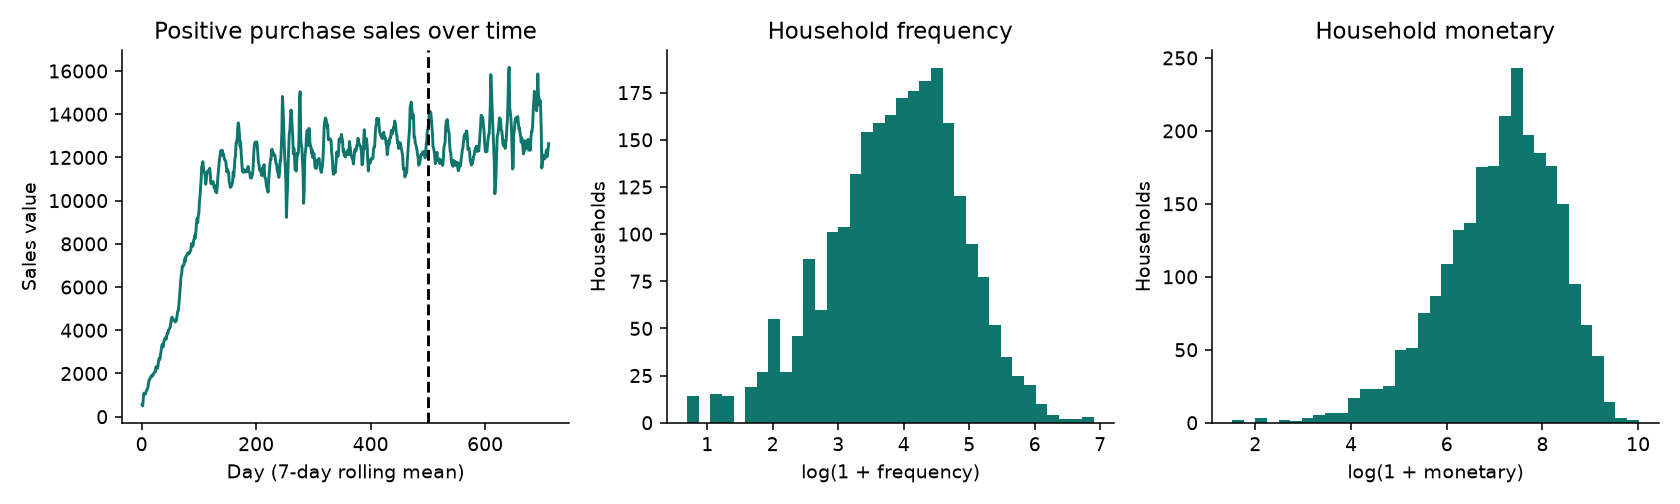

In [11]:
plt.rcParams.update(
    {
        "figure.dpi": 140,
        "font.size": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
clean.groupby("DAY").SALES_VALUE.sum().rolling(7, min_periods=1).mean().plot(
    ax=ax[0], color="#0f766e"
)
ax[0].axvline(cutoff, color="black", linestyle="--")
ax[0].set(
    title="Positive purchase sales over time",
    ylabel="Sales value",
    xlabel="Day (7-day rolling mean)",
)
for c, a in zip(["frequency", "monetary"], ax[1:]):
    a.hist(np.log1p(hh[c]), bins=35, color="#0f766e")
    a.set(title=f"Household {c}", xlabel=f"log(1 + {c})", ylabel="Households")
fig.tight_layout()
fig.savefig(FIG / "01_eda.png")
plt.close(fig)
show_fig("01_eda.png")

**Interpretation.** Recorded sales ramp up during roughly the first 100 days (as households enrol in the loyalty panel) and then plateau at about 12,000 per day, so the later period (after the dashed line) is comparable in level with the end of the calibration window. After a log transform, frequency and monetary value are roughly bell-shaped, which suits distance-based clustering; without it a few very heavy shoppers would dominate the distances.

### 4.4 Feature selection and scaling: three feature spaces

We compare three nested feature spaces: **RFM** (3 features, the baseline), **Behavior** (RFM plus 5 behavioural features, 8 in total) and **Product** (Behavior plus 9 category coordinates, 17 in total). Positive count and value features are transformed with `log(1+x)` and then standardized using calibration data only. Category shares are square-rooted (Hellinger-style coordinates), centered, and scaled so that the whole category block has the same total variance as the behaviour block; otherwise nine category columns would dominate eight behaviour columns simply by number. The correlation table below shows which behavioural features carry overlapping information.

In [12]:
# Square roots of composition produce Hellinger-style coordinates. Standardize behavioral variables; give composition block equal total variance to behavioral block.
rfm = ["recency", "frequency", "monetary"]
behavior = rfm + [
    "mean_basket_value",
    "mean_basket_lines",
    "product_breadth",
    "department_breadth",
    "discount_line_share",
]
logs = hh.copy()
for c in logs.columns:
    if c != "discount_line_share":
        logs[c] = np.log1p(logs[c])
R = StandardScaler().fit_transform(logs[rfm])
B = StandardScaler().fit_transform(logs[behavior])
C = np.sqrt(composition.to_numpy())
C = C - C.mean(axis=0)
C = C * np.sqrt(B.shape[1] / np.var(C, axis=0).sum())
spaces = {"RFM": R, "Behavior": B, "Product": np.column_stack([B, C])}
display(logs[behavior].corr().round(2))

,recency,frequency,monetary,mean_basket_value,mean_basket_lines,product_breadth,department_breadth,discount_line_share
recency,1.00,-0.63,-0.60,-0.08,-0.08,-0.58,-0.53,-0.02
frequency,-0.63,1.00,0.86,-0.04,-0.03,0.82,0.73,0.05
monetary,-0.60,0.86,1.00,0.48,0.43,0.96,0.84,0.05
mean_basket_value,-0.08,-0.04,0.48,1.00,0.90,0.44,0.36,-0.00
mean_basket_lines,-0.08,-0.03,0.43,0.90,1.00,0.51,0.38,0.07
product_breadth,-0.58,0.82,0.96,0.44,0.51,1.00,0.86,0.10
department_breadth,-0.53,0.73,0.84,0.36,0.38,0.86,1.00,0.00
discount_line_share,-0.02,0.05,0.05,-0.00,0.07,0.10,0.00,1.00


**Interpretation.** Frequency, monetary value, product breadth and department breadth are highly correlated, which is why the three spaces will turn out to be related but not identical. We keep all features rather than dropping correlated ones, because the study question is precisely whether the extra information changes the segments.

### 4.5 Audit and provenance record

We now store the complete audit (cohort sizes, exclusions, feature dimensions, policies) as `results/audit.json` and a provenance file with the data source, package versions and SHA-256 checksums of the two raw files.

In [13]:
audit.update(
    {
        "calibration_rows": len(train),
        "holdout_rows": len(future),
        "calibration_households": len(hh),
        "holdout_only_households": int(
            len(set(future.household_key) - set(hh.index))
        ),
        "top_departments": top,
        "feature_dimensions": {k: v.shape[1] for k, v in spaces.items()},
        "duplicate_policy": "Retain exact source rows; repeated product scans cannot be established as errors.",
        "cleaning_policy": "Exclude nonpositive quantity or sales; all analysis concerns positive purchase activity.",
    }
)
(OUT / "audit.json").write_text(json.dumps(audit, indent=2))
provenance = {
    "source": URL,
    "source_page": "https://www.kaggle.com/datasets/frtgnn/dunnhumby-the-complete-journey",
    "run_utc": pd.Timestamp.now(tz="UTC").isoformat(),
    "packages": {
        p: importlib.metadata.version(p)
        for p in ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib"]
    },
    "python": platform.python_version(),
    "file_sha256": {
        n: hashlib.sha256((RAW / n).read_bytes()).hexdigest()
        for n in ["transaction_data.csv", "product.csv"]
    },
}
(OUT / "provenance.json").write_text(json.dumps(provenance, indent=2))
display(pd.Series(audit["feature_dimensions"], name="features").to_frame())

,features
RFM,3
Behavior,8
Product,17


## 5. Clustering algorithms: K-means, Ward hierarchical clustering and DBSCAN

### 5.1 Scoring helper

`score(X, y)` summarizes a partition: number of clusters, noise fraction (DBSCAN only), smallest and largest cluster size, silhouette, and Davies-Bouldin index. The silhouette is computed on a fixed random sample of at most 1,500 points (`random_state=42`) for speed. Noise points (label -1) are excluded from the silhouette and Davies-Bouldin calculation, so for DBSCAN these scores must always be read together with the noise fraction.

In [14]:
rows = []
labels = {}
stability = []

def score(X, y):
    valid = y != -1
    yy = y[valid]
    ncl = len(set(yy))
    counts = pd.Series(yy).value_counts()
    return {
        "clusters": ncl,
        "noise_fraction": float((~valid).mean()),
        "min_cluster_size": int(counts.min()) if len(counts) else 0,
        "max_cluster_share": float(counts.max() / len(y)) if len(counts) else 0,
        "silhouette": (
            float(
                silhouette_score(
                    X[valid],
                    yy,
                    sample_size=min(1500, valid.sum()),
                    random_state=42,
                )
            )
            if 1 < ncl < len(yy)
            else np.nan
        ),
        "davies_bouldin": (
            float(davies_bouldin_score(X[valid], yy))
            if 1 < ncl < len(yy)
            else np.nan
        ),
    }

### 5.2 Fitting all models

For each feature space we fit **K-means** and **Ward** agglomerative clustering for k = 2 to 8 (K-means uses 20 initializations, `random_state=42`). **DBSCAN** has no k; we set `min_samples=10` and choose `eps` at four quantiles (0.5, 0.7, 0.85, 0.95) of every household's distance to its 10th nearest neighbour, which is the usual k-distance heuristic. All labels are kept in the `labels` dictionary and all metrics in one table, `model_metrics.csv`.

In [15]:
for name, X in spaces.items():
    for algo in ["KMeans", "Ward"]:
        for k in range(2, 9):
            model = (
                KMeans(n_clusters=k, n_init=20, random_state=42)
                if algo == "KMeans"
                else AgglomerativeClustering(n_clusters=k, linkage="ward")
            )
            y = model.fit_predict(X)
            labels[(name, algo, k)] = y
            rows.append(
                {
                    "space": name,
                    "algorithm": algo,
                    "parameter": k,
                    "inertia": (
                        float(model.inertia_) if algo == "KMeans" else np.nan
                    ),
                    **score(X, y),
                }
            )
    distances = NearestNeighbors(n_neighbors=10).fit(X).kneighbors(X)[0][:, -1]
    for q in [0.5, 0.7, 0.85, 0.95]:
        eps = float(np.quantile(distances, q))
        y = DBSCAN(eps=eps, min_samples=10).fit_predict(X)
        labels[(name, "DBSCAN", q)] = y
        rows.append(
            {
                "space": name,
                "algorithm": "DBSCAN",
                "parameter": q,
                "eps": eps,
                **score(X, y),
            }
        )
metrics = pd.DataFrame(rows)
metrics.to_csv(OUT / "model_metrics.csv", index=False)
display(metrics.round(3))

,space,algorithm,parameter,inertia,clusters,noise_fraction,min_cluster_size,max_cluster_share,silhouette,davies_bouldin,eps
0,RFM,KMeans,2.00,3603.127,2,0.000,882,0.647,0.456,0.857,NaN
1,RFM,KMeans,3.00,2568.396,3,0.000,397,0.441,0.357,0.970,NaN
2,RFM,KMeans,4.00,2121.805,4,0.000,257,0.370,0.282,1.099,NaN
3,RFM,KMeans,5.00,1763.531,5,0.000,245,0.348,0.290,1.050,NaN
4,RFM,KMeans,6.00,1522.351,6,0.000,181,0.230,0.293,1.034,NaN
5,RFM,KMeans,7.00,1377.328,7,0.000,162,0.237,0.282,1.017,NaN
6,RFM,KMeans,8.00,1263.808,8,0.000,144,0.209,0.267,1.068,NaN
7,RFM,Ward,2.00,NaN,2,0.000,1014,0.594,0.421,0.896,NaN
8,RFM,Ward,3.00,NaN,3,0.000,264,0.594,0.352,0.978,NaN
9,RFM,Ward,4.00,NaN,4,0.000,264,0.345,0.249,1.156,NaN


**Interpretation.** DBSCAN either collapses almost every household into one cluster (larger `eps`) or labels a third of the households as noise (smaller `eps`), so it does not yield a useful partition on these dense, continuous features. K-means and Ward both give k = 2 as the best-scoring solution in every space.

### 5.3 Model selection: silhouette curves and elbow

Two complementary selection tools are plotted for each feature space. The silhouette curve (first figure) rewards well-separated, compact clusters; we pick the k with the highest silhouette. The elbow curve (second figure) plots K-means within-cluster sum of squares against k and looks for a bend after which extra clusters add little.

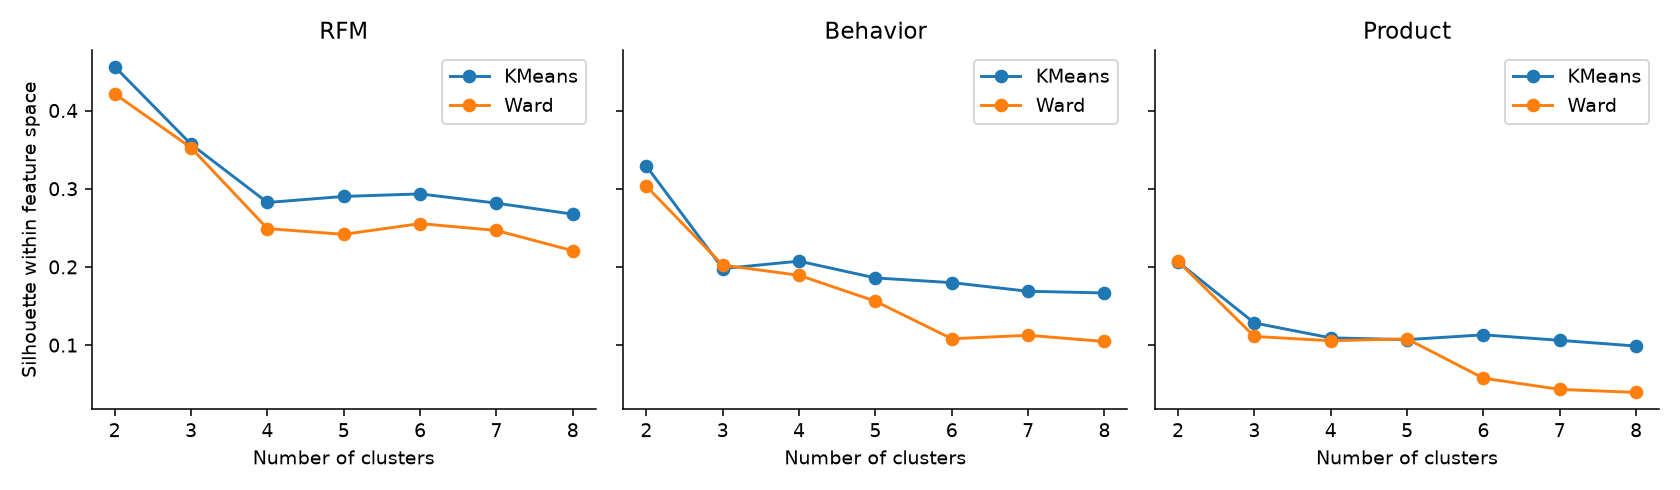

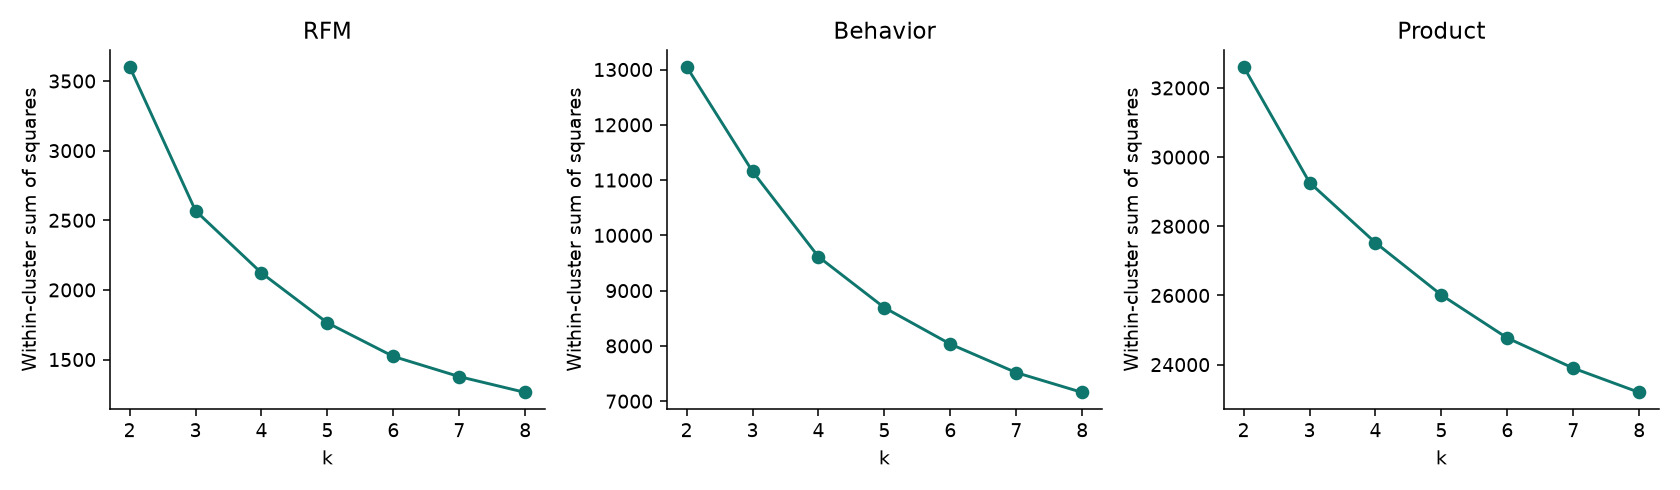

In [16]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for name, ax in zip(spaces, axs):
    for algo in ["KMeans", "Ward"]:
        m = metrics[(metrics.space == name) & (metrics.algorithm == algo)]
        ax.plot(m.parameter, m.silhouette, "o-", label=algo)
    ax.set(title=name, xlabel="Number of clusters")
    ax.legend()
axs[0].set_ylabel("Silhouette within feature space")
fig.tight_layout()
fig.savefig(FIG / "02_model_selection.png")
plt.close(fig)
show_fig("02_model_selection.png")

fig, axs = plt.subplots(1, 3, figsize=(12, 3.5))
for name, ax in zip(spaces, axs):
    m = metrics[(metrics.space == name) & (metrics.algorithm == "KMeans")]
    ax.plot(m.parameter, m.inertia, "o-", color="#0f766e")
    ax.set(title=name, xlabel="k", ylabel="Within-cluster sum of squares")
fig.tight_layout()
fig.savefig(FIG / "07_elbow.png")
plt.close(fig)
show_fig("07_elbow.png")

**Interpretation.** The silhouette is highest at k = 2 for all three spaces and falls steadily afterwards, whereas the elbow curves bend gently and without a sharp corner, so the elbow alone is ambiguous and supports k = 2 to 3. Silhouette values are measured in different spaces, so their magnitudes (0.456 for RFM, 0.329 for Behavior, 0.206 for Product) show that each space has a different geometry and must not be used to rank the feature sets.

### 5.4 Selected models

K-means k is chosen independently in each feature space as the value with the maximum silhouette, subject to every cluster holding at least 5% of households (this prevents tiny, outlier-only clusters). The selected models are saved to `selected_models.csv`.

In [17]:
# Selection before holdout: choose k by silhouette within each space, requiring >=5% households in every cluster; compare algorithms descriptively.
selected = []
for name, X in spaces.items():
    candidates = metrics[
        (metrics.space == name)
        & (metrics.algorithm == "KMeans")
        & (metrics.min_cluster_size >= 0.05 * len(hh))
    ]
    best = candidates.sort_values("silhouette", ascending=False).iloc[0]
    k = int(best.parameter)
    base = labels[(name, "KMeans", k)]
    selected.append(
        {"space": name, "algorithm": "KMeans", "k": k, **score(X, base)}
    )
pd.DataFrame(selected).to_csv(OUT / "selected_models.csv", index=False)
display(pd.DataFrame(selected))

,space,algorithm,k,clusters,noise_fraction,min_cluster_size,max_cluster_share,silhouette,davies_bouldin
0,RFM,KMeans,2,2,0.0,882,0.646918,0.456049,0.857458
1,Behavior,KMeans,2,2,0.0,809,0.676141,0.328838,1.236959
2,Product,KMeans,2,2,0.0,843,0.662530,0.206288,1.984419


## 6. Evaluation: baseline comparison, stability and later-period check

### 6.1 Stability of the selected partitions

A good segmentation should not change when the algorithm is re-run or the data are slightly perturbed. For each selected model we run (a) 20 K-means fits with a single random initialization and (b) 20 paired fits on two independent 80% subsamples, for both K-means and Ward. The Adjusted Rand Index (ARI, 1 = identical partitions, 0 = chance agreement) is computed on the households the two subsamples share. Preprocessing is held fixed, so this measures clustering sensitivity only.

mean    min    max
space    algorithm kind                               
Behavior KMeans    initialization  0.982  0.969  1.000
                   subsample       0.970  0.923  0.995
         Ward      subsample       0.457  0.154  0.740
Product  KMeans    initialization  0.997  0.981  1.000
                   subsample       0.964  0.860  0.990
         Ward      subsample       0.314 -0.024  0.584
RFM      KMeans    initialization  0.994  0.987  0.998
                   subsample       0.980  0.948  1.000
         Ward      subsample       0.535  0.011  0.874

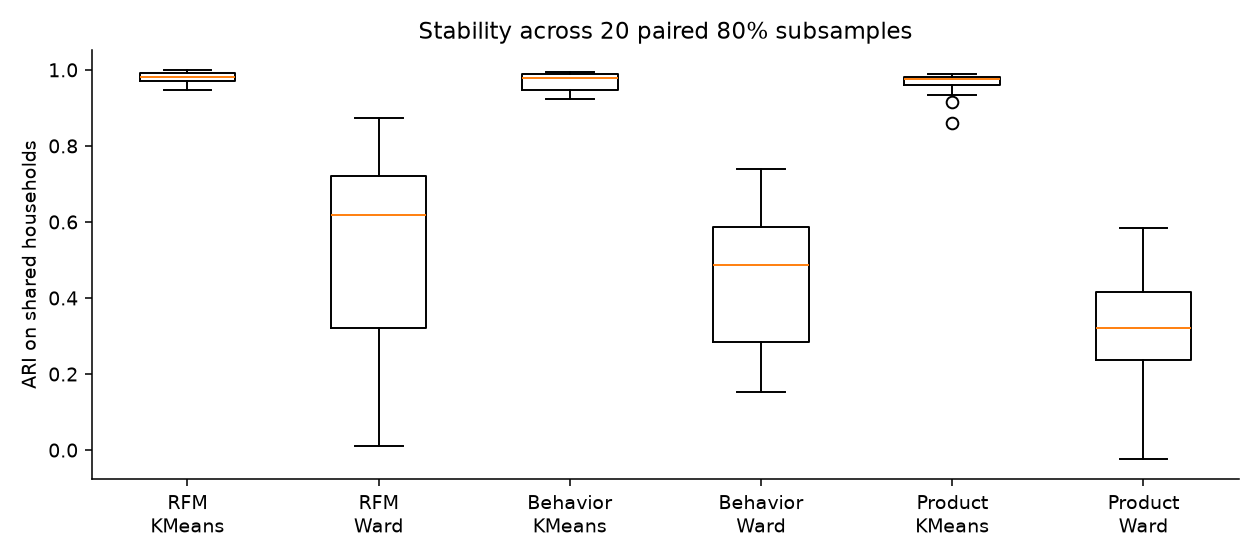

In [18]:
for s in selected:
    name, k = s["space"], s["k"]
    X = spaces[name]
    base = labels[(name, "KMeans", k)]
    # Repeated initialization and paired independent 80% refits. Fixed preprocessing isolates clustering sensitivity.
    for seed in range(20):
        y = KMeans(n_clusters=k, n_init=1, random_state=seed).fit_predict(X)
        stability.append(
            {
                "space": name,
                "algorithm": "KMeans",
                "kind": "initialization",
                "repeat": seed,
                "ari": adjusted_rand_score(base, y),
                "shared_n": len(hh),
            }
        )
    for algo in ["KMeans", "Ward"]:
        for seed in range(20):
            rng = np.random.default_rng(seed)
            a = np.sort(rng.choice(len(hh), int(0.8 * len(hh)), replace=False))
            b = np.sort(rng.choice(len(hh), int(0.8 * len(hh)), replace=False))
            common, ia, ib = np.intersect1d(a, b, return_indices=True)

            def fit(ids):
                return (
                    KMeans(n_clusters=k, n_init=20, random_state=seed)
                    if algo == "KMeans"
                    else AgglomerativeClustering(n_clusters=k)
                ).fit_predict(X[ids])

            ya, yb = fit(a), fit(b)
            stability.append(
                {
                    "space": name,
                    "algorithm": algo,
                    "kind": "subsample",
                    "repeat": seed,
                    "ari": adjusted_rand_score(ya[ia], yb[ib]),
                    "shared_n": len(common),
                }
            )

stab = pd.DataFrame(stability)
stab.to_csv(OUT / "stability_replicates.csv", index=False)
stab.groupby(["space", "algorithm", "kind"]).ari.agg(
    [
        "mean",
        "median",
        "min",
        "max",
        lambda s: s.quantile(0.025),
        lambda s: s.quantile(0.975),
    ]
).to_csv(OUT / "stability_summary.csv")
display(stab.groupby(["space", "algorithm", "kind"]).ari.agg(["mean", "min", "max"]).round(3))

fig, ax = plt.subplots(figsize=(9, 4))
groups = [(n, a) for n in spaces for a in ["KMeans", "Ward"]]
ax.boxplot(
    [
        stab[
            (stab.space == n) & (stab.algorithm == a) & (stab.kind == "subsample")
        ].ari
        for n, a in groups
    ],
    tick_labels=[f"{n}\n{a}" for n, a in groups],
)
ax.set(
    ylabel="ARI on shared households",
    title="Stability across 20 paired 80% subsamples",
)
fig.tight_layout()
fig.savefig(FIG / "03_stability.png")
plt.close(fig)
show_fig("03_stability.png")

**Interpretation.** K-means is very stable at k = 2 (mean subsample ARI 0.980 for RFM, 0.970 for Behavior and 0.964 for Product), whereas Ward is much less stable (0.535, 0.457 and 0.314) because hierarchical merges are sensitive to which households are present. This is a second reason, besides the silhouette, to prefer K-means.

### 6.2 Fixed k = 3 ablation

The selected k is 2 in each space, so differences between spaces could simply reflect different numbers of clusters. To compare feature spaces fairly we also force k = 3 everywhere, record the silhouette and Davies-Bouldin index, evaluate every partition in the *common RFM space* (`common_rfm_scores.csv`), and repeat the subsample stability test.

In [19]:
fixed_rows = []
fixed_stability = []
common_scores = []
for name, X in spaces.items():
    k = 3
    base = labels[(name, "KMeans", k)]
    fixed_rows.append({"space": name, "k": k, **score(X, base)})
    common_scores.append(
        {"labels_from": name, "k": 3, "evaluation_space": "RFM", **score(R, base)}
    )
    for seed in range(20):
        rng = np.random.default_rng(seed)
        a = np.sort(rng.choice(len(hh), int(0.8 * len(hh)), replace=False))
        b = np.sort(rng.choice(len(hh), int(0.8 * len(hh)), replace=False))
        common, ia, ib = np.intersect1d(a, b, return_indices=True)
        ya = KMeans(n_clusters=k, n_init=20, random_state=seed).fit_predict(X[a])
        yb = KMeans(n_clusters=k, n_init=20, random_state=seed).fit_predict(X[b])
        fixed_stability.append(
            {
                "space": name,
                "k": k,
                "repeat": seed,
                "ari": adjusted_rand_score(ya[ia], yb[ib]),
                "shared_n": len(common),
            }
        )
pd.DataFrame(common_scores).to_csv(OUT / "common_rfm_scores.csv", index=False)
pd.DataFrame(fixed_rows).to_csv(OUT / "fixed_k_metrics.csv", index=False)
pd.DataFrame(fixed_stability).to_csv(OUT / "fixed_k_stability.csv", index=False)
display(pd.DataFrame(fixed_rows).round(3))
display(pd.DataFrame(common_scores).round(3))
display(pd.read_csv(OUT / "fixed_k_stability.csv").groupby("space").ari.agg(["mean", "min", "max"]).round(3))

,space,k,clusters,noise_fraction,min_cluster_size,max_cluster_share,silhouette,davies_bouldin
0,RFM,3,3,0.0,397,0.441,0.357,0.970
1,Behavior,3,3,0.0,614,0.388,0.198,1.492
2,Product,3,3,0.0,677,0.453,0.128,1.951


,labels_from,k,evaluation_space,clusters,noise_fraction,min_cluster_size,max_cluster_share,silhouette,davies_bouldin
0,RFM,3,RFM,3,0.0,397,0.441,0.357,0.970
1,Behavior,3,RFM,3,0.0,614,0.388,0.138,2.733
2,Product,3,RFM,3,0.0,677,0.453,0.079,2.860


,mean,min,max
space,,,
Behavior,0.763,0.204,0.997
Product,0.929,0.872,0.985
RFM,0.970,0.872,0.996


**Interpretation.** At k = 3 the RFM partition has the best silhouette (0.357 versus 0.198 and 0.128) and the lowest Davies-Bouldin value. Judged in the common RFM space, the Behavior and Product partitions score much worse (0.138 and 0.079), meaning their clusters cut across the RFM geometry. Behavior K-means is also less stable at k = 3 (mean ARI 0.763) than RFM (0.970).

### 6.3 Sensitivity to the weight of the category block

Because the category block's weight is a modelling choice, we multiply its coordinates by 0.5 and 2 (variance multipliers 0.25 and 4), refit K-means with k = 3 and align the labels to the equal-weight solution. ARI and the number of households that switch cluster show how arbitrary the product-aware partition is.

In [20]:
sensitivity = []
baseline = labels[("Product", "KMeans", 3)]
weight_labels = pd.DataFrame(index=hh.index)
for weight in [0.5, 1, 2]:
    X = np.column_stack([B, C * weight])
    yy = baseline if weight == 1 else KMeans(
        n_clusters=3, n_init=20, random_state=42
    ).fit_predict(X)
    weight_labels[weight] = align_labels(baseline, yy)
    sensitivity.append(
        {
            "category_coordinate_multiplier": weight,
            "k": 3,
            "ari_to_equal_block": adjusted_rand_score(baseline, yy),
            "switched_vs_equal_block": int((weight_labels[weight] != baseline).sum()),
            **score(X, yy),
        }
    )
pd.DataFrame(sensitivity).to_csv(
    OUT / "category_weight_sensitivity.csv", index=False
)
weight_labels.to_csv(OUT / "category_weight_assignments.csv")
display(pd.DataFrame(sensitivity).round(3))

,category_coordinate_multiplier,k,ari_to_equal_block,switched_vs_equal_block,clusters,noise_fraction,min_cluster_size,max_cluster_share,silhouette,davies_bouldin
0,0.5,3,0.433,620,3,0.0,683,0.384,0.146,1.764
1,1.0,3,1.000,0,3,0.0,677,0.453,0.128,1.951
2,2.0,3,0.460,585,3,0.0,493,0.494,0.170,2.082


**Interpretation.** Halving or doubling the category weight changes 620 and 585 of 2,498 households (ARI 0.433 and 0.460). The product-aware k = 3 partition is therefore strongly dependent on an arbitrary weighting choice, which limits any claim that it is the uniquely correct segmentation.

### 6.4 Later-period spending (DAY 501-711)

Each calibration household receives its later-period spend and number of baskets; the 59 households with no later purchase are kept with zeros so that the cohort does not change. The statistic `eta^2` is the share of variance in later spend that lies between clusters, a descriptive measure of how well the segments separate future spending. This is a business criterion that naturally favours the monetary baseline feature, and it is **not** a prediction test.

In [21]:
# Holdout zeros preserve all calibration households, including those who make no subsequent purchases.
fut = (
    future.groupby("household_key")
    .agg(
        future_spend=("SALES_VALUE", "sum"), future_baskets=("BASKET_ID", "nunique")
    )
    .reindex(hh.index, fill_value=0)
)
fut["future_active"] = (fut.future_baskets > 0).astype(int)
fixed_hold = []
for name in spaces:
    yy = labels[(name, "KMeans", 3)]
    ff = fut.assign(cluster=yy)
    mu = fut.future_spend.mean()
    total = ((fut.future_spend - mu) ** 2).sum()
    fixed_hold.append(
        {
            "space": name,
            "k": 3,
            "future_spend_eta_squared": sum(
                len(g) * (g.future_spend.mean() - mu) ** 2
                for _, g in ff.groupby("cluster")
            )
            / total,
        }
    )
pd.DataFrame(fixed_hold).to_csv(OUT / "fixed_k_holdout.csv", index=False)
display(pd.DataFrame(fixed_hold).round(4))

,space,k,future_spend_eta_squared
0,RFM,3,0.313
1,Behavior,3,0.215
2,Product,3,0.170


### 6.5 Paired bootstrap: Product minus RFM

To judge whether the Product partition separates later spend better or worse than RFM, we resample households 1,000 times (same resample for both partitions) and report the difference in eta^2 with a 95% percentile interval. The interval is conditional on the already fitted labels.

In [22]:
# Paired household bootstrap: descriptive Product-minus-RFM future-spend grouping difference.
differences = []
values = fut.future_spend.to_numpy()
rng = np.random.default_rng(2026)
for mode, k in [("selected", 2), ("fixed", 3)]:
    yr = labels[("RFM", "KMeans", k)]
    yp = labels[("Product", "KMeans", k)]

    def eta(v, y):
        mean = v.mean()
        total = ((v - mean) ** 2).sum()
        return (
            sum(
                (y == c).sum() * (v[y == c].mean() - mean) ** 2
                for c in np.unique(y)
            )
            / total
        )

    point = eta(values, yp) - eta(values, yr)
    boots = []
    for _ in range(1000):
        ids = rng.integers(0, len(values), len(values))
        boots.append(eta(values[ids], yp[ids]) - eta(values[ids], yr[ids]))
    differences.append(
        {
            "comparison": "Product minus RFM",
            "mode": mode,
            "k": k,
            "eta_squared_difference": point,
            "conditional_ci_low": np.quantile(boots, 0.025),
            "conditional_ci_high": np.quantile(boots, 0.975),
        }
    )
pd.DataFrame(differences).to_csv(
    OUT / "holdout_paired_differences.csv", index=False
)
display(pd.DataFrame(differences).round(4))

,comparison,mode,k,eta_squared_difference,conditional_ci_low,conditional_ci_high
0,Product minus RFM,selected,2,-0.0019,-0.0143,0.0086
1,Product minus RFM,fixed,3,-0.1430,-0.1652,-0.1188


**Interpretation.** At the selected k = 2 the difference is -0.0019 with interval [-0.0143, 0.0086], which includes zero: adding behaviour and category features does not improve later-spend separation. At k = 3 the Product partition is clearly worse (-0.143, interval [-0.165, -0.119]).

### 6.6 Cluster profiles, holdout summary and uncertainty

For each selected model we export household-level assignments, cluster mean profiles, the category composition of each cluster, the eta^2 and Kruskal-Wallis statistic for later spend, and bootstrap confidence intervals for each cluster's mean later spend. The agreement table gives the ARI between the three selected partitions.

In [23]:
profiles = []
hold = []
uncertainty = []
for s in selected:
    name = s["space"]
    y = labels[(name, "KMeans", s["k"])]
    frame = hh.join(fut)
    frame["cluster"] = y
    frame.to_csv(OUT / f"households_{name.lower()}.csv")
    prof = frame.groupby("cluster").mean()
    prof["n"] = frame.groupby("cluster").size()
    prof["space"] = name
    profiles.append(prof.reset_index())
    for c, g in frame.groupby("cluster"):
        rng = np.random.default_rng(42 + c)
        vals = g.future_spend.to_numpy()
        boots = np.array(
            [rng.choice(vals, len(vals), replace=True).mean() for _ in range(1000)]
        )
        uncertainty.append(
            {
                "space": name,
                "cluster": c,
                "n": len(g),
                "mean_future_spend": vals.mean(),
                "mean_ci_low": np.quantile(boots, 0.025),
                "mean_ci_high": np.quantile(boots, 0.975),
                "future_active_rate": g.future_active.mean(),
            }
        )
    # Between-cluster explained variance of future spend, descriptive only.
    mu = fut.future_spend.mean()
    ss_total = ((fut.future_spend - mu) ** 2).sum()
    ss_between = sum(
        len(g) * (g.future_spend.mean() - mu) ** 2
        for _, g in frame.groupby("cluster")
    )
    hold.append(
        {
            "space": name,
            "n": len(frame),
            "inactive_households": int((frame.future_active == 0).sum()),
            "future_spend_eta_squared": ss_between / ss_total,
            "kruskal_statistic": kruskal(
                *[g.future_spend for _, g in frame.groupby("cluster")]
            ).statistic,
        }
    )
    comp = composition.assign(cluster=y).groupby("cluster").mean()
    comp.to_csv(OUT / f"composition_{name.lower()}.csv")
pd.concat(profiles).to_csv(OUT / "cluster_profiles.csv", index=False)
pd.DataFrame(hold).to_csv(OUT / "holdout_summary.csv", index=False)
pd.DataFrame(uncertainty).to_csv(OUT / "holdout_uncertainty.csv", index=False)
agreement = []
for a in spaces:
    for b in spaces:
        ka = next(s["k"] for s in selected if s["space"] == a)
        kb = next(s["k"] for s in selected if s["space"] == b)
        agreement.append(
            {
                "space_a": a,
                "space_b": b,
                "ari": adjusted_rand_score(
                    labels[(a, "KMeans", ka)], labels[(b, "KMeans", kb)]
                ),
            }
        )
pd.DataFrame(agreement).to_csv(OUT / "cross_space_agreement.csv", index=False)
display(pd.DataFrame(hold).round(4))
display(pd.DataFrame(uncertainty).round(3))
display(pd.DataFrame(agreement).pivot(index="space_a", columns="space_b", values="ari").round(3))

,space,n,inactive_households,future_spend_eta_squared,kruskal_statistic
0,RFM,2498,59,0.2038,918.0122
1,Behavior,2498,59,0.1971,941.9308
2,Product,2498,59,0.2019,923.3434


,space,cluster,n,mean_future_spend,mean_ci_low,mean_ci_high,future_active_rate
0,RFM,0,882,343.247,318.257,371.220,0.939
1,RFM,1,1616,1487.486,1424.009,1547.029,0.997
2,Behavior,0,809,306.295,280.689,332.087,0.937
3,Behavior,1,1689,1455.730,1393.712,1516.794,0.995
4,Product,0,1655,1471.947,1413.711,1535.557,0.995
5,Product,1,843,320.818,297.566,347.109,0.941


space_b,Behavior,Product,RFM
space_a,,,
Behavior,1.000,0.850,0.614
Product,0.850,1.000,0.589
RFM,0.614,0.589,1.000


**Interpretation.** All three selected models split households into a small low-spend group and a large high-spend group. In the later period the low-spend cluster spends roughly 306 to 343 on average versus about 1,456 to 1,487 for the high-spend cluster, with non-overlapping bootstrap intervals. The selected partitions agree moderately (ARI 0.59 between RFM and Product, 0.61 between RFM and Behavior, 0.85 between Behavior and Product).

### 6.7 What the Product clusters look like

The first heatmap shows the mean category spend share of each Product cluster, the second the deviation from the all-household mean in percentage points. The PCA scatter plot is an illustrative two-dimensional projection of the Product feature space coloured by cluster; it is not independent evidence of cluster quality. The later-period spend plot (figure 05) shows the mean later spend of each cluster with a 95% bootstrap interval.

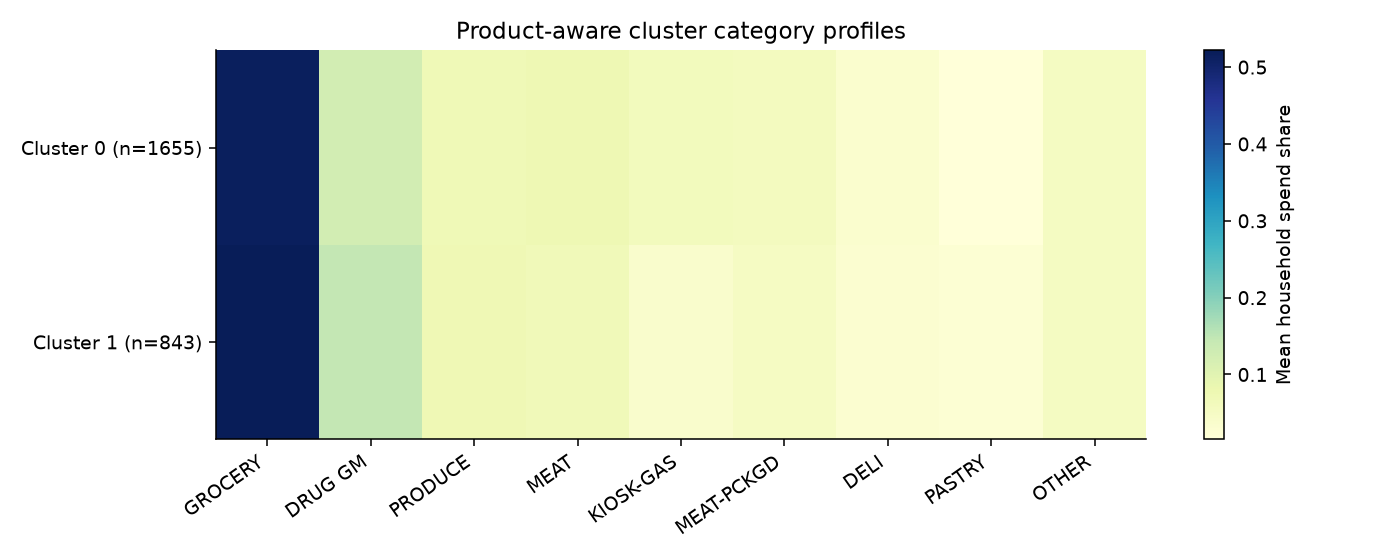

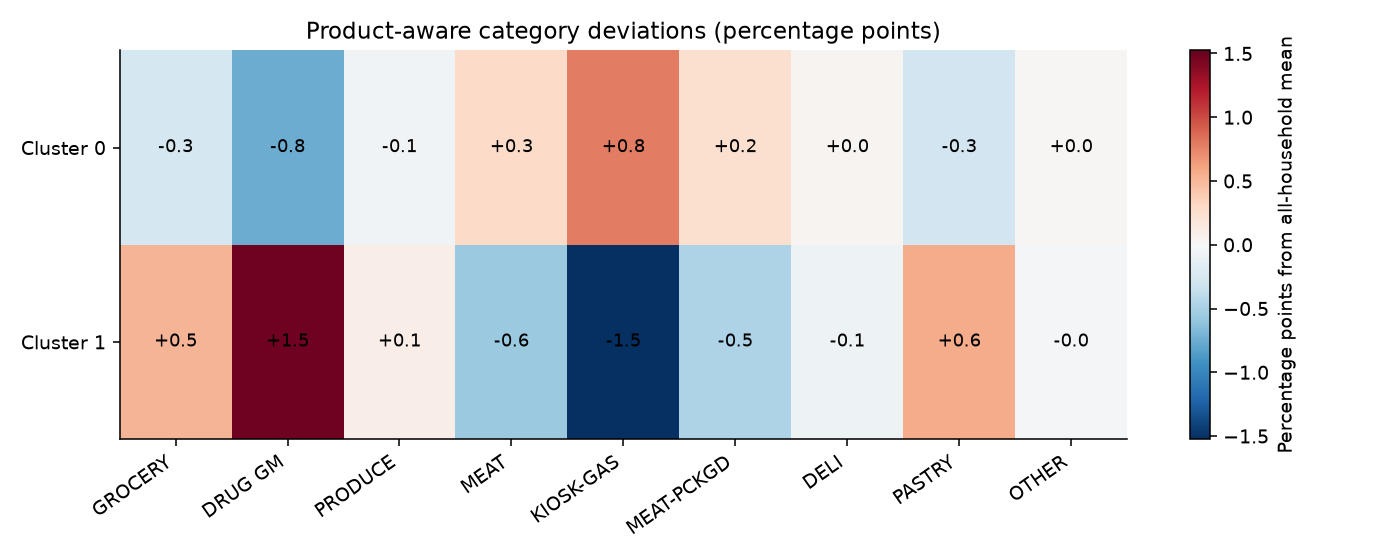

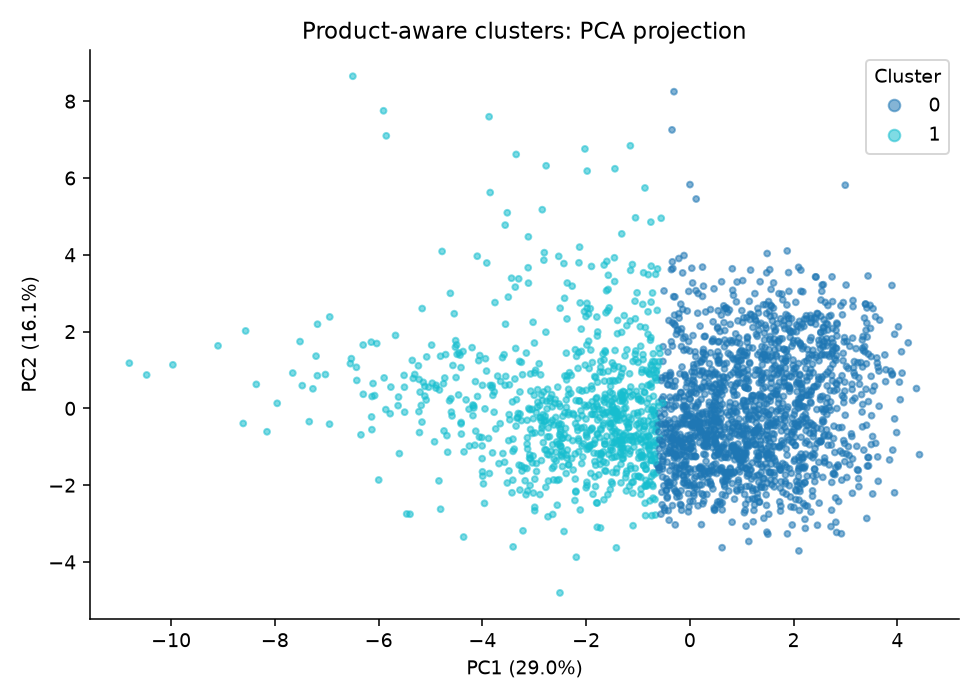

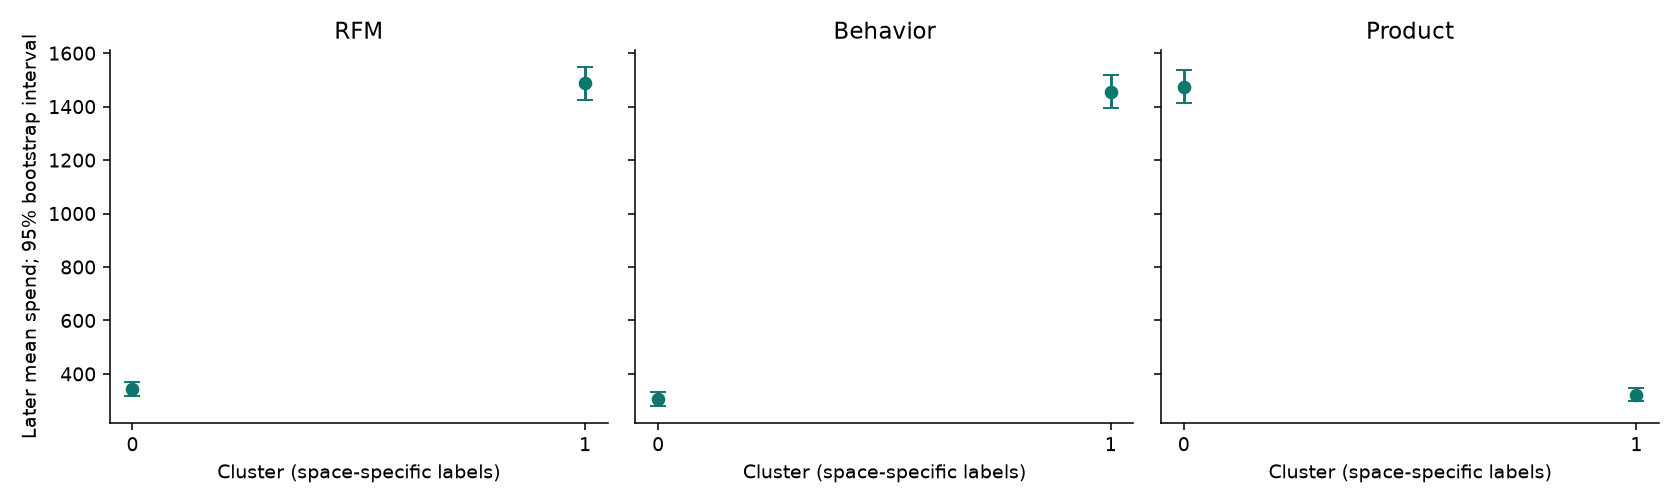

In [24]:
product_k = next(s["k"] for s in selected if s["space"] == "Product")
yy = labels[("Product", "KMeans", product_k)]
comp = composition.assign(cluster=yy).groupby("cluster").mean()
fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(comp, cmap="YlGnBu", aspect="auto")
ax.set_xticks(range(comp.shape[1]), comp.columns, rotation=35, ha="right")
ax.set_yticks(
    range(len(comp)), [f"Cluster {c} (n={(yy==c).sum()})" for c in comp.index]
)
fig.colorbar(im, ax=ax, label="Mean household spend share")
ax.set_title("Product-aware cluster category profiles")
fig.tight_layout()
fig.savefig(FIG / "04_category_profiles.png")
plt.close(fig)
deviations = (comp - composition.mean()) * 100
fig, ax = plt.subplots(figsize=(10, 4))
vmax = max(abs(deviations.to_numpy()).max(), 1)
im = ax.imshow(deviations, cmap="RdBu_r", aspect="auto", vmin=-vmax, vmax=vmax)
ax.set_xticks(range(comp.shape[1]), comp.columns, rotation=35, ha="right")
ax.set_yticks(range(len(comp)), [f"Cluster {c}" for c in comp.index])
for i in range(len(comp)):
    for j in range(comp.shape[1]):
        ax.text(
            j,
            i,
            f"{deviations.iloc[i,j]:+.1f}",
            ha="center",
            va="center",
            fontsize=9,
        )
fig.colorbar(im, ax=ax, label="Percentage points from all-household mean")
ax.set_title("Product-aware category deviations (percentage points)")
fig.tight_layout()
fig.savefig(FIG / "08_category_deviations.png")
plt.close(fig)
show_fig("04_category_profiles.png")
show_fig("08_category_deviations.png")

pca = PCA(n_components=2).fit(spaces["Product"])
xy = pca.transform(spaces["Product"])
fig, ax = plt.subplots(figsize=(7, 5))
scatter = ax.scatter(xy[:, 0], xy[:, 1], c=yy, cmap="tab10", s=9, alpha=0.55)
ax.set(
    title="Product-aware clusters: PCA projection",
    xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.1%})",
    ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.1%})",
)
ax.legend(*scatter.legend_elements(), title="Cluster")
fig.tight_layout()
fig.savefig(FIG / "06_pca.png")
plt.close(fig)
show_fig("06_pca.png")

u = pd.DataFrame(uncertainty)
fig, axs = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for name, ax in zip(spaces, axs):
    a = u[u.space == name]
    ax.errorbar(
        a.cluster,
        a.mean_future_spend,
        yerr=[
            a.mean_future_spend - a.mean_ci_low,
            a.mean_ci_high - a.mean_future_spend,
        ],
        fmt="o",
        capsize=4,
        color="#0f766e",
    )
    ax.set(title=name, xlabel="Cluster (space-specific labels)")
    ax.set_xticks(a.cluster)
axs[0].set_ylabel("Later mean spend; 95% bootstrap interval")
fig.tight_layout()
fig.savefig(FIG / "05_holdout.png")
plt.close(fig)
show_fig("05_holdout.png")

**Interpretation.** Category deviations between the two selected Product clusters are small (at most about 1.5 percentage points), so the segments are mainly activity-level groups rather than distinct product-preference groups. The PCA projection shows one continuous cloud split roughly along its first axis, not isolated islands, which is consistent with DBSCAN finding no density-separated groups. Figure 05 confirms that in every space the high-spend cluster has much higher later spend, with clearly separated intervals.

### 6.8 Supplementary analyses: household cases, weight flows and later category preferences

The helper functions defined earlier are now called. They (a) pick one representative household for each changed RFM-to-Product transition, (b) draw how households flow between clusters as the category weight changes, and (c) compare category spending profiles of the same later-active households in the calibration and later periods, using the same eta^2 metric and a paired 1,000-resample contrast.

,rfm_cluster,product_cluster,product_aligned_cluster,households
0,0,0,1,163
1,0,1,0,719
2,1,0,1,1492
3,1,1,0,124


,household_key,recency,frequency,monetary,mean_basket_value,mean_basket_lines,product_breadth,department_breadth,discount_line_share,GROCERY,...,PRODUCE,MEAT,KIOSK-GAS,MEAT-PCKGD,DELI,PASTRY,OTHER,rfm_cluster,product_cluster,product_aligned_cluster
0,2389,33,43,1102.61,25.642093,10.348837,342,13,0.552809,0.547320,...,0.078214,0.129429,0.018139,0.055731,0.027154,0.014266,0.048177,0,0,1
1,1970,7,44,615.01,13.977500,6.340909,214,8,0.491039,0.665257,...,0.012162,0.035008,0.000000,0.079527,0.006569,0.008114,0.014276,1,1,0


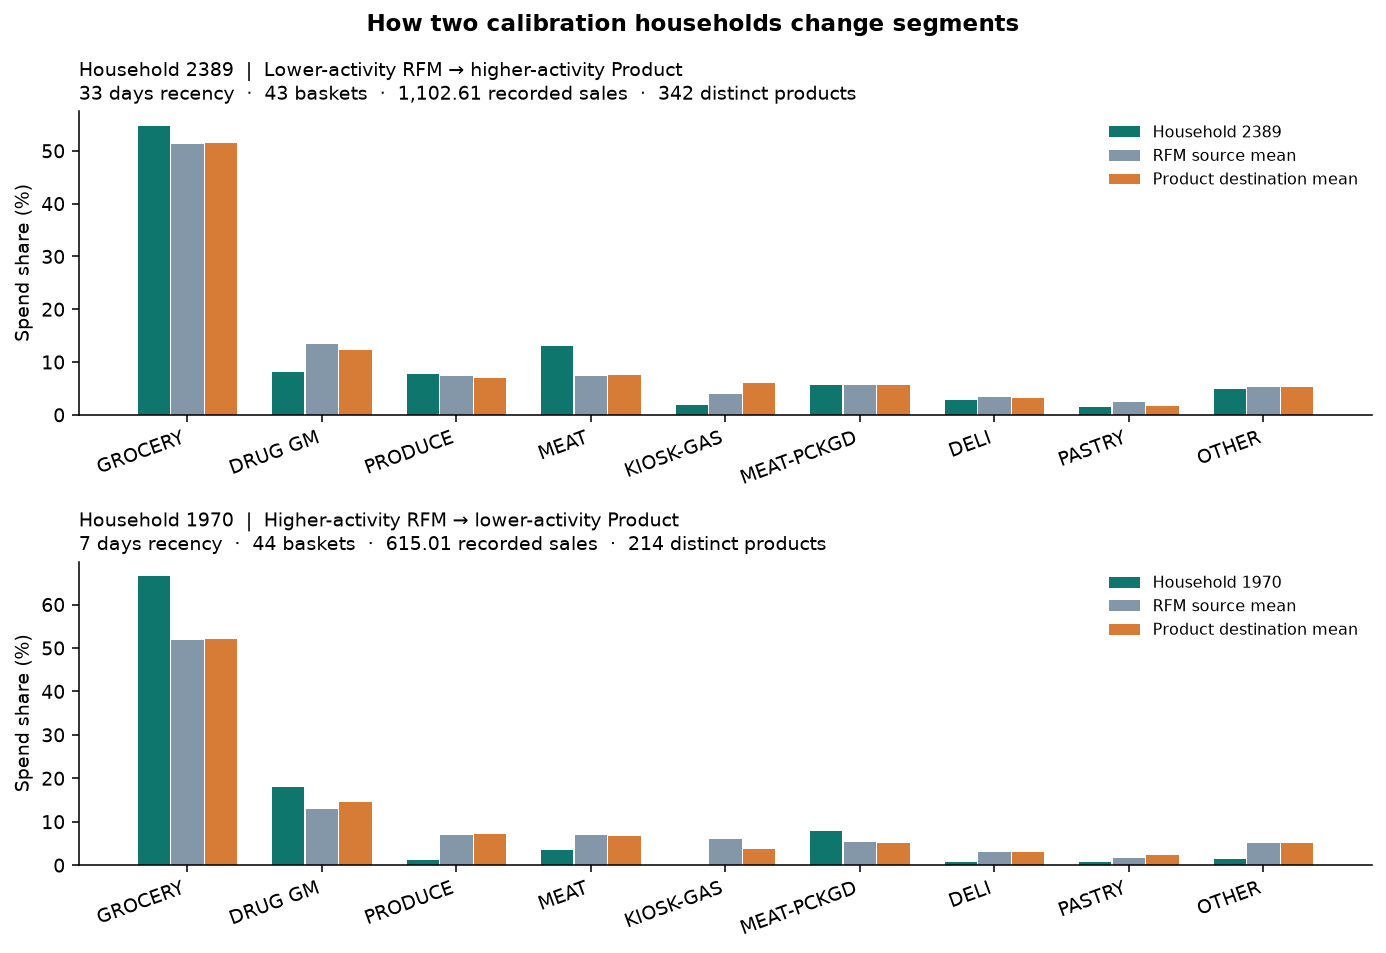

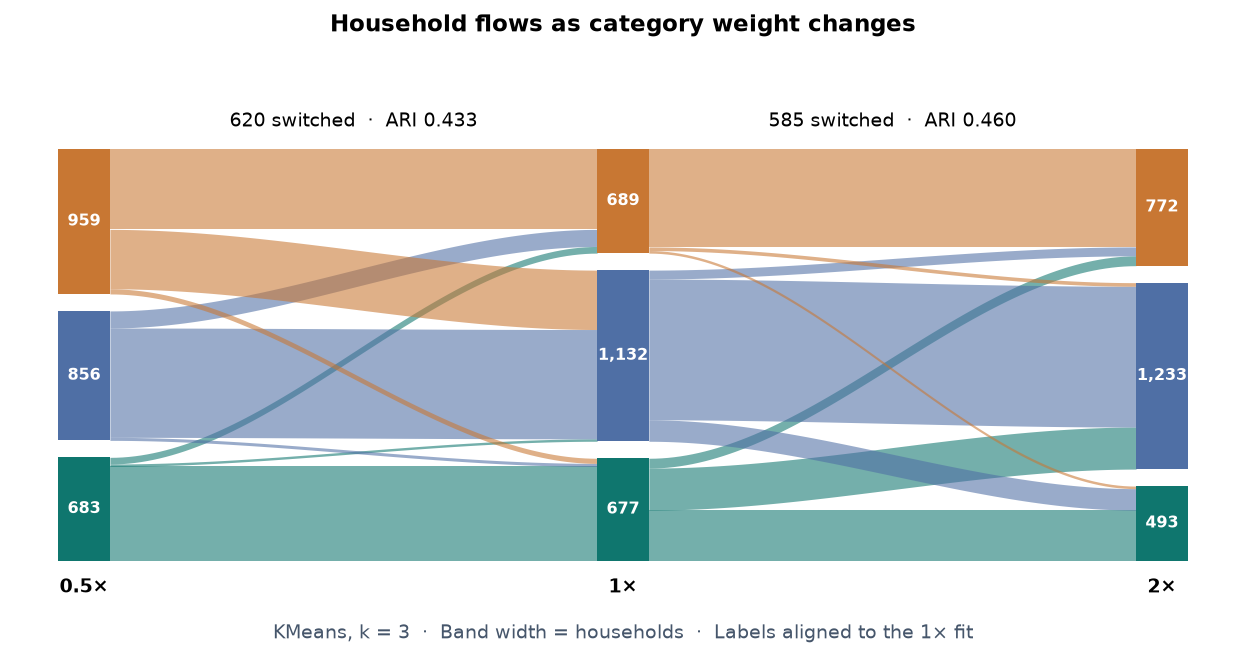

holdout_category_summary.csv


,space,k,calibration_households,active_households,calibration_category_eta_squared,future_category_eta_squared
0,RFM,2,2498,2439,0.002503,0.002992
1,Behavior,2,2498,2439,0.002206,0.001798
2,Product,2,2498,2439,0.005285,0.003860


holdout_category_activity.csv


,space,cluster,calibration_households,active_households,future_active_rate
0,RFM,0,882,828,0.938776
1,RFM,1,1616,1611,0.996906
2,Behavior,0,809,758,0.936959
3,Behavior,1,1689,1681,0.995263
4,Product,0,1655,1646,0.994562
5,Product,1,843,793,0.940688


holdout_category_paired_difference.csv


,comparison,active_households,eta_squared_difference,conditional_ci_low,conditional_ci_high,bootstrap_draws
0,Product minus RFM,2439,0.000868,-0.001097,0.003148,1000


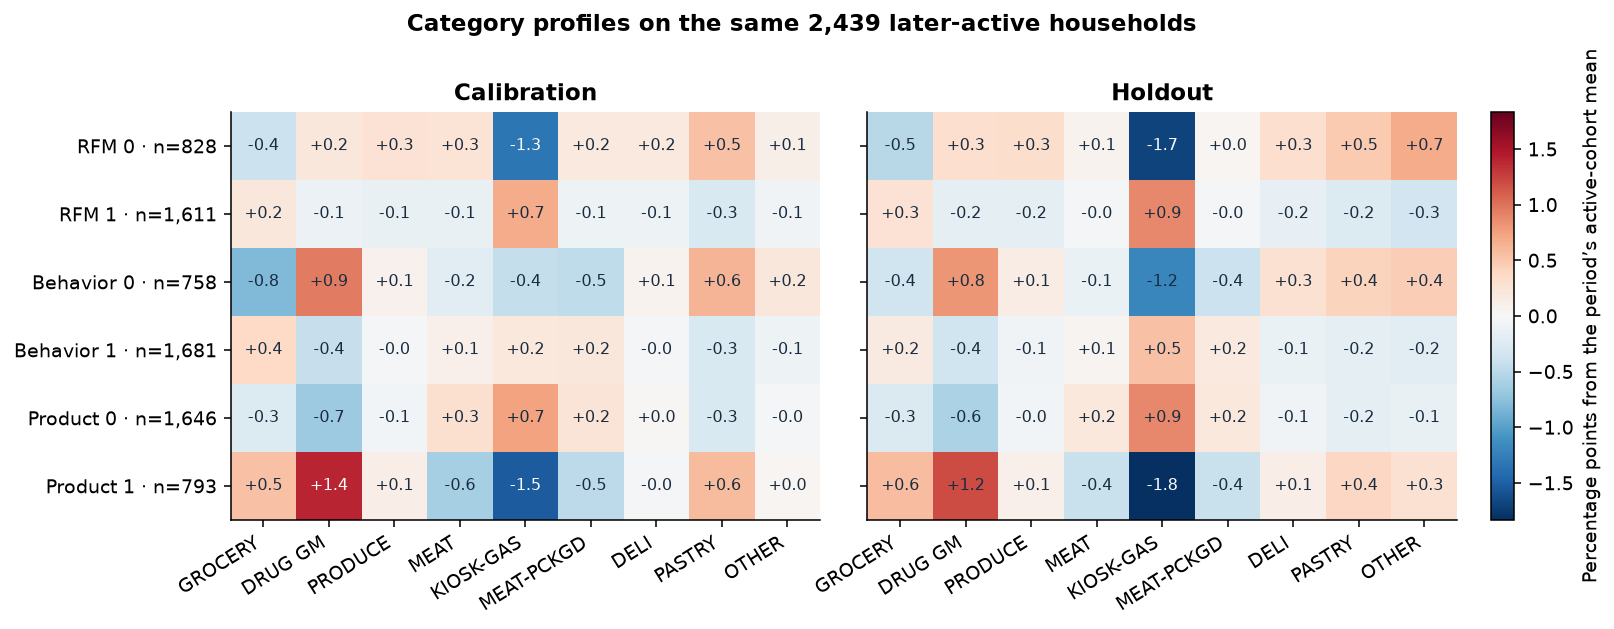

In [25]:
household_cases(hh, composition, labels, spaces["Product"])
weight_flow(weight_labels)
heldout_categories(
    future, composition, fut.future_active.astype(bool),
    {s["space"]: labels[(s["space"], "KMeans", s["k"])] for s in selected},
)
display(pd.read_csv(OUT / "rfm_product_transitions.csv"))
display(pd.read_csv(OUT / "household_cases.csv"))
show_fig("10_household_cases.png")
show_fig("11_category_flow.png")

for file in ["holdout_category_summary.csv", "holdout_category_activity.csv", "holdout_category_paired_difference.csv"]:
    print(file)
    display(pd.read_csv(OUT / file))
show_fig("12_future_categories.png")

**Interpretation.** About 287 households (11.5%) change segment when category information is added to RFM. The flow figure shows that many more households move when the category weight is changed at k = 3. Category-share eta^2 is tiny in both periods (about 0.002 to 0.005), and the Product-minus-RFM contrast on later-active households (+0.0009, interval [-0.0011, +0.0031]) includes zero, so the product-aware segments do not show materially stronger category preferences either.

### 6.9 Collected results

For convenience the main objects are gathered in a dictionary and the headline tables are printed once more.

In [26]:
results = {
    "audit": audit,
    "metrics": metrics,
    "selected": pd.DataFrame(selected),
    "stability": stab,
    "holdout": pd.DataFrame(hold),
}
print("SELECTED")
display(results["selected"].round(3))
print("HOLDOUT")
display(results["holdout"].round(4))
print("STABILITY")
display(results["stability"].groupby(["space", "algorithm", "kind"]).ari.agg(["mean", "min", "max"]).round(3))

SELECTED


,space,algorithm,k,clusters,noise_fraction,min_cluster_size,max_cluster_share,silhouette,davies_bouldin
0,RFM,KMeans,2,2,0.0,882,0.647,0.456,0.857
1,Behavior,KMeans,2,2,0.0,809,0.676,0.329,1.237
2,Product,KMeans,2,2,0.0,843,0.663,0.206,1.984


HOLDOUT


,space,n,inactive_households,future_spend_eta_squared,kruskal_statistic
0,RFM,2498,59,0.2038,918.0122
1,Behavior,2498,59,0.1971,941.9308
2,Product,2498,59,0.2019,923.3434


STABILITY


mean    min    max
space    algorithm kind                               
Behavior KMeans    initialization  0.982  0.969  1.000
                   subsample       0.970  0.923  0.995
         Ward      subsample       0.457  0.154  0.740
Product  KMeans    initialization  0.997  0.981  1.000
                   subsample       0.964  0.860  0.990
         Ward      subsample       0.314 -0.024  0.584
RFM      KMeans    initialization  0.994  0.987  0.998
                   subsample       0.980  0.948  1.000
         Ward      subsample       0.535  0.011  0.874

### 6.10 Extension A: business personas (RFM, k = 4)

The statistical selection chooses k = 2 for every space, which separates high from low activity but gives marketing little to act on. As a complementary **interpretive** view, K-means is refit on the same standardized log-RFM coordinates with k = 4 (20 initializations, seed 42). This does not replace the k = 2 result; it re-slices the same activity gradient into four named tiers. Personas are ordered by mean calibration spend, and the later period (days 501–711) is used only to describe them.

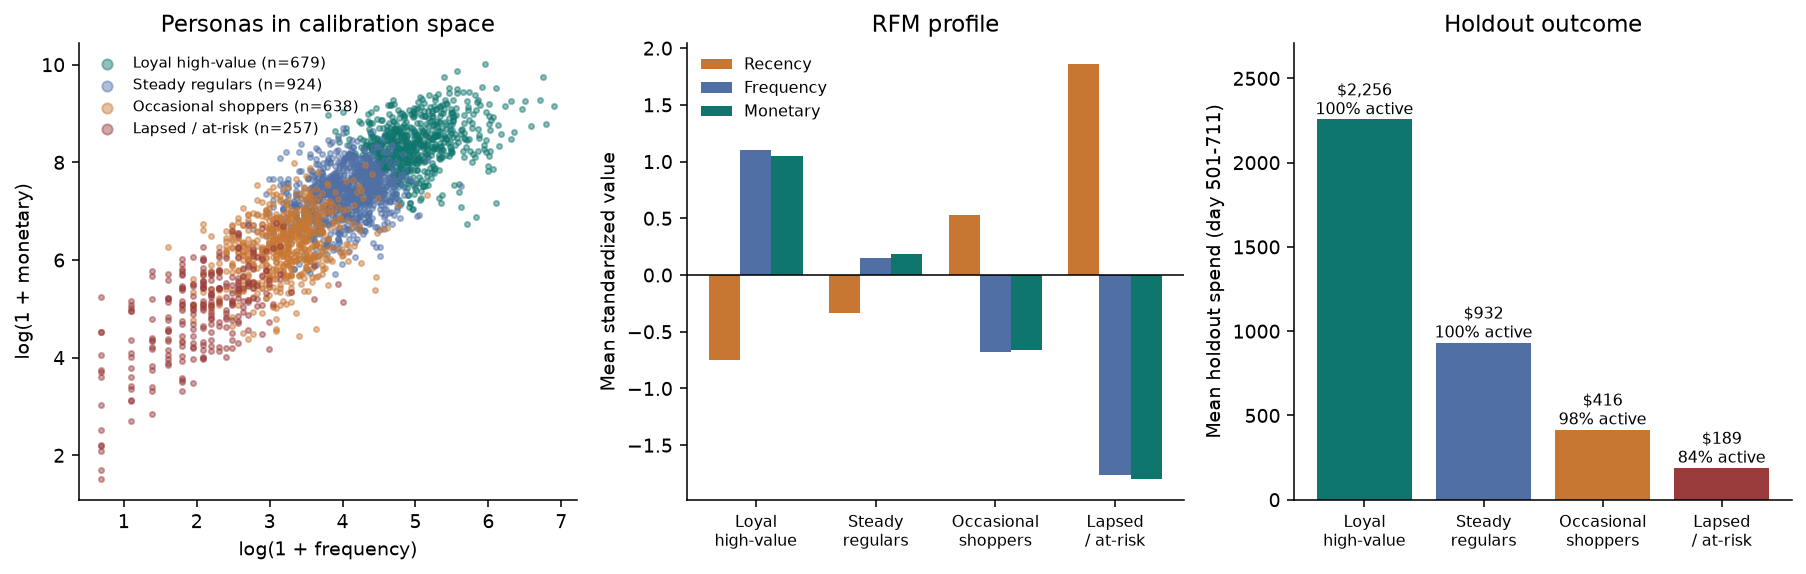

Silhouette k=4: 0.293 | k=2: 0.451 | subsample ARI mean 0.93 (min 0.39)


,persona,households,share_pct,recency_mean,recency_median,frequency_mean,frequency_median,monetary_mean,monetary_median,future_spend_mean,future_spend_median,future_baskets_mean,future_active_rate,holdout_spend_share_pct,silhouette_k4,silhouette_k2,ari_mean,ari_min,ari_max
0,Loyal high-value,679,27.182,3.427,2.0,165.916,134.0,4840.661,4222.830,2256.303,1950.170,72.542,0.997,56.605,0.293,0.451,0.927,0.392,0.996
1,Steady regulars,924,36.990,7.659,5.0,59.802,57.0,1721.625,1589.865,931.557,767.635,30.719,0.997,31.803,0.293,0.451,0.927,0.392,0.996
2,Occasional shoppers,638,25.540,30.125,18.0,26.524,23.0,663.047,558.130,415.719,283.200,14.257,0.981,9.800,0.293,0.451,0.927,0.392,0.996
3,Lapsed / at-risk,257,10.288,160.553,110.0,8.883,7.0,195.188,163.570,188.732,73.470,6.529,0.837,1.792,0.293,0.451,0.927,0.392,0.996


In [27]:
# Extension A: RFM personas (k = 4). Same log1p + standardisation as the main RFM space.
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

RFM = ["recency", "frequency", "monetary"]
SEED, K = 42, 4

hh = pd.read_csv(OUT / "households_rfm.csv")  # frozen household table from Section 5

# Same transformation as src/analysis.py: log1p, then standardize.
X = StandardScaler().fit_transform(np.log1p(hh[RFM]))


def fit(data, k, seed=SEED):
    return KMeans(n_clusters=k, n_init=20, random_state=seed).fit_predict(data)


raw4, raw2 = fit(X, K), fit(X, 2)
sil4, sil2 = silhouette_score(X, raw4), silhouette_score(X, raw2)

# Deterministic ordering: by mean monetary value, descending.
hh["raw"] = raw4
order = hh.groupby("raw").monetary.mean().sort_values(ascending=False).index
rank = {c: i for i, c in enumerate(order)}
hh["rank"] = hh.raw.map(rank)

# Persona names follow the profile.  Rank 0 = highest spend; rank 3 = lowest
# spend.  The checks below make the names fail loudly if the profile changes.
names = {0: "Loyal high-value", 1: "Steady regulars",
         2: "Occasional shoppers", 3: "Lapsed / at-risk"}
rec = hh.groupby("rank").recency.mean()
frq = hh.groupby("rank").frequency.mean()
assert rec.idxmax() == 3, "lowest-spend persona is no longer the most lapsed"
assert frq.is_monotonic_decreasing and rec.idxmin() == 0, "profile ordering changed"
hh["persona"] = hh["rank"].map(names)

# Profiles: sizes, mean/median R/F/M, holdout (day 501-711) outcomes.
rows = []
for r, name in names.items():
    g = hh[hh["rank"] == r]
    row = {"persona": name, "households": len(g), "share_pct": 100 * len(g) / len(hh)}
    for c in RFM:
        row[f"{c}_mean"], row[f"{c}_median"] = g[c].mean(), g[c].median()
    row.update(future_spend_mean=g.future_spend.mean(),
               future_spend_median=g.future_spend.median(),
               future_baskets_mean=g.future_baskets.mean(),
               future_active_rate=g.future_active.mean())
    rows.append(row)
prof = pd.DataFrame(rows)
tot = hh.future_spend.sum()
prof["holdout_spend_share_pct"] = [
    100 * hh.loc[hh["rank"] == r, "future_spend"].sum() / tot for r in names]
prof["silhouette_k4"], prof["silhouette_k2"] = sil4, sil2

# Stability: ARI of each 80% subsample fit against the full-sample labels,
# evaluated on the subsample rows (20 draws, seed 42).
rng = np.random.default_rng(SEED)
ari = []
for _ in range(20):
    idx = rng.choice(len(X), int(0.8 * len(X)), replace=False)
    ari.append(adjusted_rand_score(raw4[idx], fit(X[idx], K)))
prof["ari_mean"], prof["ari_min"], prof["ari_max"] = np.mean(ari), np.min(ari), np.max(ari)
prof.round(4).to_csv(OUT / "rfm_personas_profiles.csv", index=False)
hh[["household_key", "persona"]].to_csv(OUT / "rfm_personas_assignments.csv", index=False)

# Figure, in the style of the existing figures (teal accent, no top/right spines).
plt.rcParams.update({"figure.dpi": 140, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
cols = ["#0f766e", "#4f6fa5", "#c87733", "#9a3b3b"]
fig, ax = plt.subplots(1, 3, figsize=(13, 4.2))
for r, name in names.items():
    g = hh[hh["rank"] == r]
    ax[0].scatter(np.log1p(g.frequency), np.log1p(g.monetary), s=7, alpha=0.45,
                  color=cols[r], label=f"{name} (n={len(g):,})")
ax[0].set(xlabel="log(1 + frequency)", ylabel="log(1 + monetary)",
          title="Personas in calibration space")
ax[0].legend(fontsize=7.5, frameon=False, loc="upper left", markerscale=2)
labels = [n.replace(" ", "\n", 1) for n in names.values()]
zs = pd.DataFrame(X, columns=RFM).groupby(hh["rank"].values).mean()
w = 0.26
for i, (c, lab) in enumerate(zip(RFM, ["Recency", "Frequency", "Monetary"])):
    ax[1].bar(np.arange(4) + (i - 1) * w, zs[c], w, label=lab,
              color=["#c87733", "#4f6fa5", "#0f766e"][i])
ax[1].axhline(0, color="black", linewidth=0.8)
ax[1].set_xticks(range(4), labels, fontsize=8)
ax[1].set(ylabel="Mean standardized value", title="RFM profile")
ax[1].legend(fontsize=8, frameon=False)
ax[2].bar(range(4), prof.future_spend_mean, color=cols)
for i, (v, a) in enumerate(zip(prof.future_spend_mean, prof.future_active_rate)):
    ax[2].text(i, v, f"${v:,.0f}\n{100*a:.0f}% active", ha="center", va="bottom", fontsize=8)
ax[2].set_xticks(range(4), labels, fontsize=8)
ax[2].set(ylabel="Mean holdout spend (day 501-711)", title="Holdout outcome")
ax[2].set_ylim(0, prof.future_spend_mean.max() * 1.2)
fig.tight_layout()
fig.savefig(FIG / "13_rfm_personas.png", bbox_inches="tight")
plt.close(fig)

show_fig("13_rfm_personas.png")
print(f"Silhouette k=4: {sil4:.3f} | k=2: {sil2:.3f} | subsample ARI mean {np.mean(ari):.2f} (min {np.min(ari):.2f})")
display(prof.round(3))

**Interpretation.** *Loyal high-value* households (about 27% of the cohort) generate more than half of later spend, while *Lapsed / at-risk* households (about 10%) have a median recency of 110 days and the lowest later activity. *Steady regulars* and *Occasional shoppers* sit in between. The k = 4 silhouette is clearly lower than k = 2 and one subsample draw was unstable, so these tiers are a communication and targeting lens, not evidence of four natural household types.

### 6.11 Extension B: external validation with unused tables
The k=2 labels are **not refit**. Demographics (`hh_demographic`) and coupon/campaign tables (`campaign_table`, `campaign_desc`, `coupon_redempt`) never entered clustering, so they give outside evidence. Higher-activity group = cluster with larger mean calibration `monetary`. Campaign analysis uses only campaigns starting after DAY 500; a targeted household *responds* if it redeems a coupon of a targeted campaign inside that campaign's window. Targeting was not random, so everything is observational. Demographics exist almost only for higher-activity households (selection caveat).

In [28]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

RAW, FIG, OUT = Path("data/raw"), Path("figures"), Path("results")
CUTOFF = 500          # calibration DAY<=500; holdout DAY>500
SEED, NBOOT = 42, 2000
COLORS = {"Higher": "#1f4e79", "Lower": "#e08a1e"}

plt.rcParams.update({"figure.dpi": 140, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})

# ---- frozen labels: label the higher-activity cluster by mean calibration spend ----
def load(space):
    d = pd.read_csv(OUT / f"households_{space}.csv")
    hi = d.groupby("cluster").monetary.mean().idxmax()
    d["group"] = np.where(d.cluster == hi, "Higher", "Lower")
    return d[["household_key", "group", "monetary"]]

labels = {"RFM": load("rfm"), "Product": load("product")}

def wilson(k, n, z=1.959964):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    den = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / den
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return c - h, c + h

def cramers_v(table):
    chi2 = chi2_contingency(table, correction=False)[0]
    return np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1)))

#### Part 1: demographics

In [29]:
# ================= Part 1: demographics =================
demo = pd.read_csv(RAW / "hh_demographic.csv")
ORDER = {
    "AGE_DESC": ["19-24", "25-34", "35-44", "45-54", "55-64", "65+"],
    "INCOME_DESC": ["Under 15K", "15-24K", "25-34K", "35-49K", "50-74K", "75-99K",
                    "100-124K", "125-149K", "150-174K", "175-199K", "200-249K", "250K+"],
    "HOUSEHOLD_SIZE_DESC": ["1", "2", "3", "4", "5+"],
    "KID_CATEGORY_DESC": ["None/Unknown", "1", "2", "3+"],
    "HOMEOWNER_DESC": ["Homeowner", "Renter", "Probable Owner", "Probable Renter", "Unknown"],
}
# Merge sparse top income bands (<30 households each) into broader bands for testing.
INCOME_MAP = {"Under 15K": "<25K", "15-24K": "<25K", "25-34K": "25-49K", "35-49K": "25-49K",
              "50-74K": "50-74K", "75-99K": "75-99K", "100-124K": "100-149K",
              "125-149K": "100-149K", "150-174K": "150K+", "175-199K": "150K+",
              "200-249K": "150K+", "250K+": "150K+"}
INCOME_ORDER = ["<25K", "25-49K", "50-74K", "75-99K", "100-149K", "150K+"]

prof_rows, test_rows, cover_rows = [], [], []
for space, lab in labels.items():
    m = lab.merge(demo, on="household_key", how="left", indicator=True)
    m["has_demo"] = m["_merge"] == "both"
    # Coverage by cluster (selection-bias check)
    ct = pd.crosstab(m.group, m.has_demo)
    chi_p = chi2_contingency(ct, correction=False)[1]
    for g in ["Higher", "Lower"]:
        s = m[m.group == g]
        lo, hi = wilson(s.has_demo.sum(), len(s))
        cover_rows.append(dict(space=space, group=g, n=len(s), with_demographics=int(s.has_demo.sum()),
                               coverage=s.has_demo.mean(), ci_low=lo, ci_high=hi,
                               coverage_diff_chi2_p=chi_p))
    d = m[m.has_demo].copy()
    d["INCOME_DESC"] = d.INCOME_DESC.map(INCOME_MAP)
    order = dict(ORDER, INCOME_DESC=INCOME_ORDER)
    for var, cats in order.items():
        d[var] = pd.Categorical(d[var].astype(str), categories=cats)
        tab = pd.crosstab(d.group, d[var]).reindex(index=["Higher", "Lower"], columns=cats)
        for g in tab.index:
            for c in cats:
                prof_rows.append(dict(space=space, variable=var, group=g, category=c,
                                      n=int(tab.loc[g, c]), share=tab.loc[g, c] / tab.loc[g].sum()))
        t = tab.loc[:, tab.sum() > 0]
        chi2, p, dof, exp = chi2_contingency(t, correction=False)
        test_rows.append(dict(space=space, variable=var, n=int(t.to_numpy().sum()), dof=dof,
                              chi2=chi2, p_value=p, cramers_v=cramers_v(t),
                              min_expected=exp.min(),
                              cells_expected_lt5=int((exp < 5).sum())))
cover = pd.DataFrame(cover_rows)
profiles = pd.DataFrame(prof_rows)
tests = pd.DataFrame(test_rows)
# Holm correction within each space across the 5 demographic tests
tests["p_holm"] = np.nan
for sp, idx in tests.groupby("space").groups.items():
    p = tests.loc[idx, "p_value"].to_numpy()
    o = np.argsort(p)
    adj = np.minimum(1, np.maximum.accumulate((len(p) - np.arange(len(p))) * p[o]))
    out = np.empty_like(adj); out[o] = adj
    tests.loc[idx, "p_holm"] = out
cov_prof = cover.rename(columns={"with_demographics": "n_with"}).assign(variable="COVERAGE")
cov_prof = pd.concat([cov_prof.assign(category="has_demographics", n=cov_prof.n_with, share=cov_prof.coverage)[["space", "variable", "group", "category", "n", "share"]],
                      cov_prof.assign(category="no_demographics", n=cov_prof.n - cov_prof.n_with, share=1 - cov_prof.coverage)[["space", "variable", "group", "category", "n", "share"]]])
pd.concat([profiles, cov_prof], ignore_index=True).to_csv(OUT / "demographic_profiles.csv", index=False)
# Coverage rows are appended to the tests file as variable='COVERAGE' for compactness
cov_tests = (cover.groupby("space").agg(n=("n", "sum"), p_value=("coverage_diff_chi2_p", "first"))
             .reset_index().assign(variable="COVERAGE (has demographics)"))
pd.concat([tests, cov_tests], ignore_index=True).to_csv(OUT / "demographic_tests.csv", index=False)

#### Part 2: campaign / coupon response

In [30]:
# ================= Part 2: campaign / coupon response =================
camp = pd.read_csv(RAW / "campaign_table.csv")
desc = pd.read_csv(RAW / "campaign_desc.csv")
red = pd.read_csv(RAW / "coupon_redempt.csv")
# Out-of-sample campaigns: those that START after the calibration cutoff.
post = desc[desc.START_DAY > CUTOFF].CAMPAIGN
tgt = camp[camp.CAMPAIGN.isin(post)][["household_key", "CAMPAIGN"]].drop_duplicates()
# A targeted (household,campaign) pair "responds" if the household redeemed a coupon of
# that campaign on a DAY inside the campaign window (and necessarily DAY>500).
rr = red.merge(desc, on="CAMPAIGN")
rr = rr[(rr.DAY >= rr.START_DAY) & (rr.DAY <= rr.END_DAY) & (rr.DAY > CUTOFF)]
resp_pairs = rr[["household_key", "CAMPAIGN"]].drop_duplicates().assign(resp=1)
pairs = tgt.merge(resp_pairs, how="left", on=["household_key", "CAMPAIGN"]).fillna({"resp": 0})
hh_t = pairs.groupby("household_key").agg(n_campaigns=("CAMPAIGN", "size"), n_resp=("resp", "sum"))
hh_t["responded"] = hh_t.n_resp > 0
# Secondary: any holdout redemption regardless of targeting data (all households)
any_red = set(red[red.DAY > CUTOFF].household_key)

def two_prop_p(k1, n1, k2, n2):
    return chi2_contingency([[k1, n1 - k1], [k2, n2 - k2]], correction=False)[1]

rng = np.random.default_rng(SEED)
resp_rows, hh_tab = [], {}
for space, lab in labels.items():
    h = lab.set_index("household_key").join(hh_t)
    h["targeted"] = h.n_campaigns.notna()
    h["responded"] = h.responded.astype("boolean").fillna(False).astype(bool)
    h["any_holdout_redemption"] = h.index.isin(any_red)
    hh_tab[space] = h
    for g in ["Higher", "Lower"]:
        s = h[h.group == g]; st = s[s.targeted]
        metrics = [
            ("targeted_share", s.targeted.sum(), len(s), "all clustered households"),
            ("responder_rate_among_targeted", st.responded.sum(), len(st), "targeted households"),
            ("pair_response_rate", st.n_resp.sum(), st.n_campaigns.sum(), "targeted household-campaign pairs"),
            ("any_holdout_redemption_all", s.any_holdout_redemption.sum(), len(s), "all clustered households"),
        ]
        for name, k, n, den in metrics:
            lo, hi = wilson(k, n)
            resp_rows.append(dict(space=space, group=g, metric=name, denominator=den,
                                  successes=int(k), n=int(n), rate=k / n, ci_low=lo, ci_high=hi))
resp = pd.DataFrame(resp_rows)

# Difference tests: Higher minus Lower, and bootstrap CI (households resampled)
def gap(h, col, cond=None):
    x = h if cond is None else h[cond(h)]
    a, b = x[x.group == "Higher"][col].mean(), x[x.group == "Lower"][col].mean()
    return a - b

diff_rows = []
boot = {}
for space, h in hh_tab.items():
    hh_idx = np.arange(len(h))
    arr = {c: h[c].to_numpy(float) for c in ["targeted", "responded", "any_holdout_redemption"]}
    grp = (h.group == "Higher").to_numpy()
    def stats(ix):
        g, t, r, a = grp[ix], arr["targeted"][ix] > 0, arr["responded"][ix], arr["any_holdout_redemption"][ix]
        def d(v, mask):
            m1, m0 = mask & g, mask & ~g
            return v[m1].mean() - v[m0].mean() if m1.any() and m0.any() else np.nan
        allm = np.ones_like(g, bool)
        return np.array([d(t.astype(float), allm), d(r.astype(float), t), d(a, allm)])
    bs = np.array([stats(rng.integers(0, len(h), len(h))) for _ in range(NBOOT)])
    boot[space] = bs
    point = stats(hh_idx)
    names = ["targeted_share", "responder_rate_among_targeted", "any_holdout_redemption_all"]
    for i, nm in enumerate(names):
        a = resp[(resp.space == space) & (resp.metric == nm)].set_index("group")
        p = two_prop_p(a.loc["Higher", "successes"], a.loc["Higher", "n"],
                       a.loc["Lower", "successes"], a.loc["Lower", "n"])
        lo, hi = np.nanpercentile(bs[:, i], [2.5, 97.5])
        diff_rows.append(dict(space=space, group="Higher minus Lower", metric=nm,
                              denominator="difference", successes=np.nan, n=np.nan,
                              rate=point[i], ci_low=lo, ci_high=hi, p_value=p))
# Cross-space contrast: is the Higher-Lower gap in responder rate different for Product vs RFM?
# (paired bootstrap on the same resampled households; index 1 = responder gap among targeted)
ix_common = hh_tab["RFM"].index.intersection(hh_tab["Product"].index)
Hr, Hp = hh_tab["RFM"].loc[ix_common], hh_tab["Product"].loc[ix_common]
def gap_c(h, ix):
    s = h.iloc[ix]; s = s[s.targeted]
    return s[s.group == "Higher"].responded.mean() - s[s.group == "Lower"].responded.mean()
cont = []
for _ in range(NBOOT):
    ix = rng.integers(0, len(ix_common), len(ix_common))
    cont.append(gap_c(Hp, ix) - gap_c(Hr, ix))
pt = gap_c(Hp, np.arange(len(ix_common))) - gap_c(Hr, np.arange(len(ix_common)))
lo, hi = np.nanpercentile(cont, [2.5, 97.5])
diff_rows.append(dict(space="Product minus RFM", group="Higher-Lower gap", metric="responder_rate_among_targeted",
                      denominator="difference of gaps", rate=pt, ci_low=lo, ci_high=hi, p_value=np.nan))
resp = pd.concat([resp, pd.DataFrame(diff_rows)], ignore_index=True)
resp.to_csv(OUT / "coupon_response.csv", index=False)

#### Figures

In [31]:
# ================= Figures =================
# Figure 14: demographic distributions per cluster (Product labels top, RFM below)
vars_ = ["AGE_DESC", "INCOME_DESC", "HOUSEHOLD_SIZE_DESC", "KID_CATEGORY_DESC", "HOMEOWNER_DESC"]
titles = {"AGE_DESC": "Age", "INCOME_DESC": "Income (USD)", "HOUSEHOLD_SIZE_DESC": "Household size",
          "KID_CATEGORY_DESC": "Kids", "HOMEOWNER_DESC": "Homeowner status"}
fig, axes = plt.subplots(2, 5, figsize=(16, 6.2), gridspec_kw={"width_ratios": [6, 6, 5, 4, 5]})
for r, space in enumerate(["RFM", "Product"]):
    for c, v in enumerate(vars_):
        ax = axes[r, c]
        p = profiles[(profiles.space == space) & (profiles.variable == v)]
        cats = list(dict.fromkeys(p.category))
        x = np.arange(len(cats))
        for k, g in enumerate(["Higher", "Lower"]):
            q = p[p.group == g].set_index("category").reindex(cats)
            ax.bar(x + (k - .5) * .38, q.share * 100, .38, color=COLORS[g], label=f"{g}-activity")
        ax.set_xticks(x, cats, rotation=40, ha="right", fontsize=8)
        t = tests[(tests.space == space) & (tests.variable == v)].iloc[0]
        ptxt = "p<0.001" if t.p_value < 0.001 else f"p={t.p_value:.3f}"
        ax.set_title(f"{titles[v]}\nV={t.cramers_v:.2f}, {ptxt}", fontsize=9, weight="bold")
        if c == 0:
            ax.set_ylabel(f"{space} labels\n% of group")
        if r == 0 and c == 0:
            ax.legend(frameon=False, fontsize=8)
ns = cover.set_index(["space", "group"]).with_demographics
fig.suptitle("Household demographics by frozen cluster (not clustering inputs). Households with demographics: "
             f"RFM {ns['RFM','Higher']} higher / {ns['RFM','Lower']} lower; "
             f"Product {ns['Product','Higher']} higher / {ns['Product','Lower']} lower", weight="bold", fontsize=11)
fig.tight_layout()
fig.savefig(FIG / "14_demographics.png", bbox_inches="tight")
plt.close(fig)

# Figure 15: coupon response by group, RFM vs Product
panels = [("targeted_share", "Targeted by a post-day-500 campaign"),
          ("responder_rate_among_targeted", "Redeemed, among targeted households")]
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for ax, (met, ttl) in zip(axs, panels):
    for i, space in enumerate(["RFM", "Product"]):
        for k, g in enumerate(["Higher", "Lower"]):
            row = resp[(resp.space == space) & (resp.group == g) & (resp.metric == met)].iloc[0]
            xx = i + (k - .5) * .36
            ax.bar(xx, row.rate * 100, .34, color=COLORS[g], label=f"{g}-activity" if i == 0 else None)
            ax.errorbar(xx, row.rate * 100, yerr=[[ (row.rate - row.ci_low) * 100], [(row.ci_high - row.rate) * 100]],
                        color="black", capsize=3, lw=1)
            ax.text(xx, row.ci_high * 100 + 1, f"{row.rate*100:.1f}%", ha="center", fontsize=8)
    ax.set_xticks([0, 1], ["RFM labels", "Product labels"])
    ax.set_ylabel("%"); ax.set_ylim(0, 100); ax.set_title(ttl, weight="bold", fontsize=10)
axs[1].legend(frameon=False, loc="upper right")
fig.suptitle("Out-of-sample campaign targeting and coupon redemption (95% Wilson intervals)", weight="bold")
fig.tight_layout()
fig.savefig(FIG / "15_coupon_response.png", bbox_inches="tight")
plt.close(fig)

# ---- console summary ----
pd.set_option("display.width", 200)
print(cover.round(4).to_string(index=False))
print(tests.round(4).to_string(index=False))
print(resp.round(4).to_string(index=False))

  space  group    n  with_demographics  coverage  ci_low  ci_high  coverage_diff_chi2_p
    RFM Higher 1616                773    0.4783  0.4541   0.5027                   0.0
    RFM  Lower  882                 28    0.0317  0.0221   0.0455                   0.0
Product Higher 1655                766    0.4628  0.4389   0.4869                   0.0
Product  Lower  843                 35    0.0415  0.0300   0.0572                   0.0
  space            variable   n  dof   chi2  p_value  cramers_v  min_expected  cells_expected_lt5  p_holm
    RFM            AGE_DESC 801    5 5.8205   0.3241     0.0852        1.6080                   4  0.9394
    RFM         INCOME_DESC 801    5 9.5423   0.0893     0.1091        1.9925                   4  0.4465
    RFM HOUSEHOLD_SIZE_DESC 801    4 4.7572   0.3131     0.0771        1.8527                   3  0.9394
    RFM   KID_CATEGORY_DESC 801    3 5.0164   0.1706     0.0791        2.0974                   3  0.6824
    RFM      HOMEOWNER_DESC 80

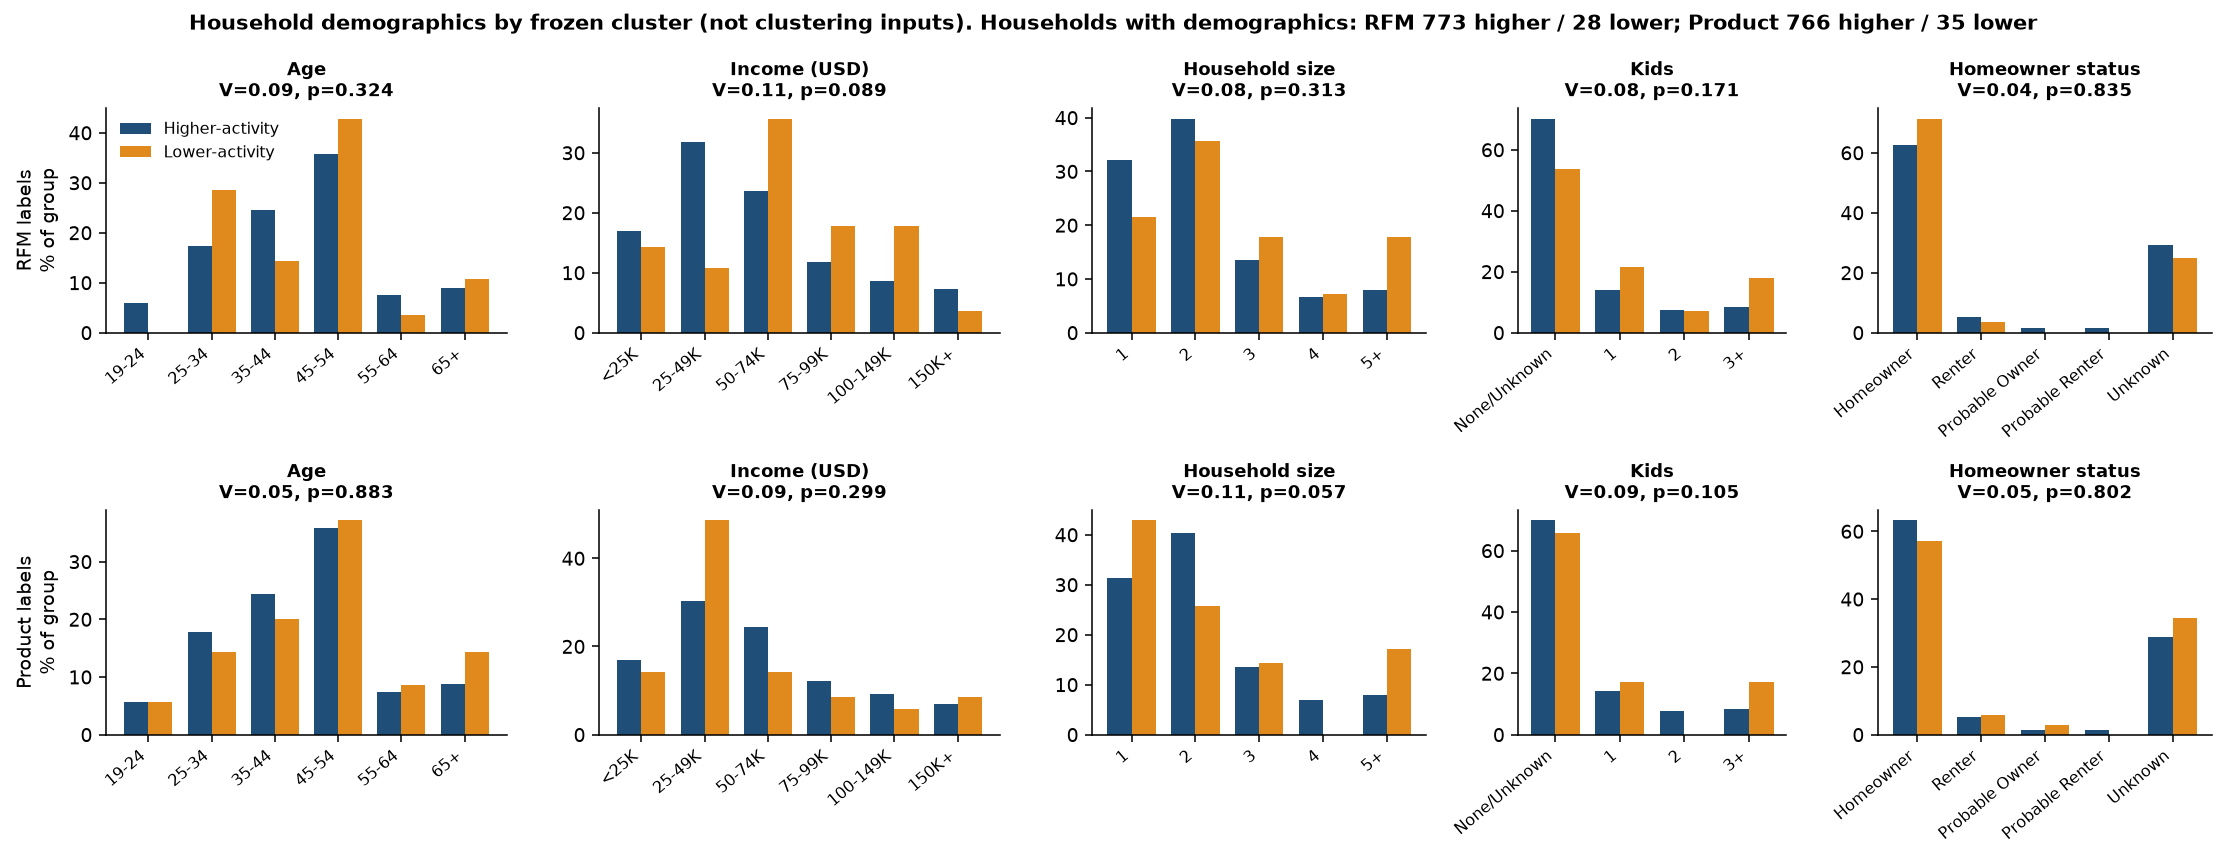

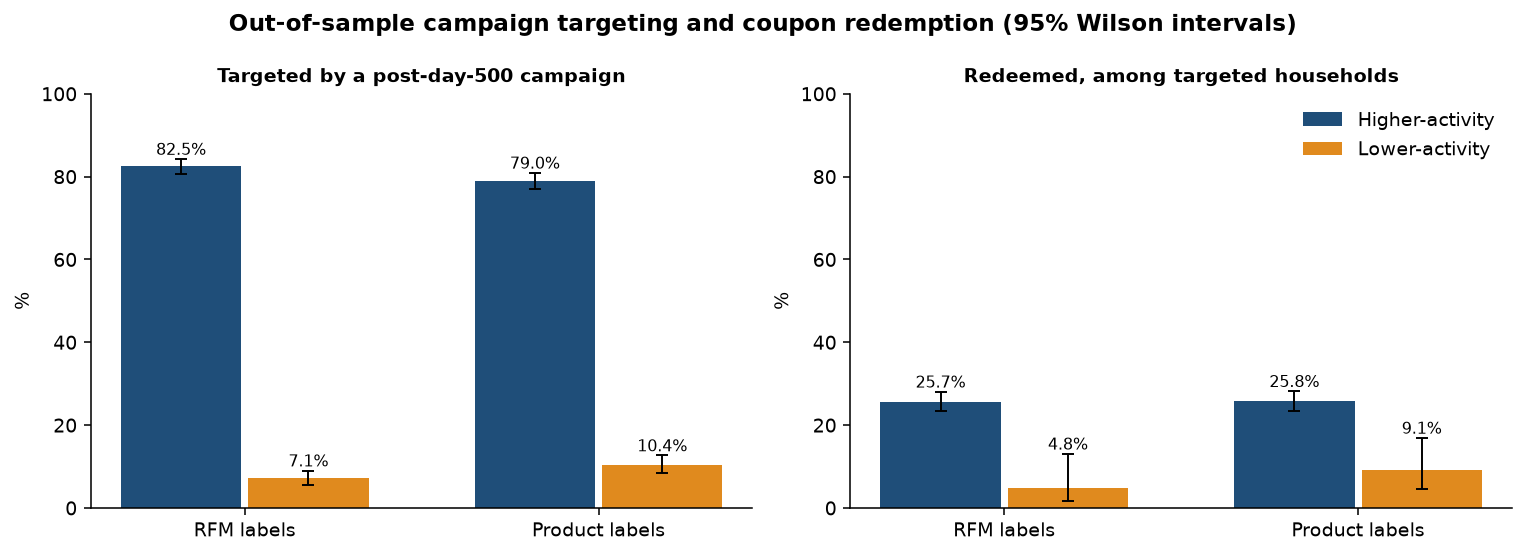

,space,group,metric,denominator,successes,n,rate,ci_low,ci_high,p_value
0,RFM,Higher,targeted_share,all clustered households,1333.0,1616.0,0.824876,0.805581,0.842631,NaN
1,RFM,Higher,responder_rate_among_targeted,targeted households,342.0,1333.0,0.256564,0.233842,0.280686,NaN
2,RFM,Higher,pair_response_rate,targeted household-campaign pairs,574.0,3952.0,0.145243,0.134602,0.156573,NaN
3,RFM,Higher,any_holdout_redemption_all,all clustered households,342.0,1616.0,0.211634,0.192414,0.232221,NaN
4,RFM,Lower,targeted_share,all clustered households,63.0,882.0,0.071429,0.056226,0.090348,NaN
5,RFM,Lower,responder_rate_among_targeted,targeted households,3.0,63.0,0.047619,0.016326,0.130910,NaN
6,RFM,Lower,pair_response_rate,targeted household-campaign pairs,3.0,74.0,0.040541,0.013882,0.112547,NaN
7,RFM,Lower,any_holdout_redemption_all,all clustered households,3.0,882.0,0.003401,0.001157,0.009952,NaN
8,Product,Higher,targeted_share,all clustered households,1308.0,1655.0,0.790332,0.770059,0.809261,NaN
9,Product,Higher,responder_rate_among_targeted,targeted households,337.0,1308.0,0.257645,0.234678,0.282032,NaN


In [32]:
show_fig("14_demographics.png")
show_fig("15_coupon_response.png")
display(pd.read_csv(OUT / "coupon_response.csv"))

**Interpretation.** Demographic records exist for roughly 48% of higher-activity households but only about 3% of lower-activity ones, so the demographic sample is effectively a higher-activity sample; within it, no demographic variable differs significantly between groups. Coupon records, which never entered clustering, confirm the activity split: among households targeted by campaigns starting after day 500, about 26% of the higher-activity group redeemed a coupon versus about 5% of the lower group. Product-aware labels do not separate responders better than RFM. Targeting was not random, so these are observational associations.

## 7. Conclusion

**Main insights.**
- The data are clean (no missing cells, duplicates or unmatched products); 18,917 of 2,595,732 lines (0.7%) were removed as non-positive purchases, leaving 2,498 calibration households (DAY 1-500), of which 59 made no purchase in the later period (DAY 501-711).
- Every method and feature space prefers a **two-segment** solution: a smaller low-activity group (about 32-35% of households) and a larger high-activity group. In the later period the low group spends about 306-343 on average against 1,456-1,487 for the high group.
- Adding behavioural and product-category features changes the assignment of some households (287, or 11.5%, between RFM and Product) but does not improve how well segments separate later spending: eta^2 is 0.2038 (RFM), 0.1971 (Behavior) and 0.2019 (Product); the Product-minus-RFM difference is -0.0019, 95% interval [-0.0143, 0.0086].
- Category differences between the Product clusters are small (at most about 1.5 percentage points), and later-period category eta^2 is near zero (0.0030 RFM, 0.0039 Product).
- A four-group RFM persona lens (Section 6.10) turns the activity gradient into actionable tiers: *Loyal high-value* households are 27.2% of the cohort but 56.6% of later spend, while *Lapsed / at-risk* households (10.3%) are the clearest reactivation target.
- External checks with tables never used for clustering (Section 6.11) support the split: among households targeted by campaigns starting after day 500, 25.7% of the RFM higher-activity group redeemed a coupon versus 4.8% of the lower group. Product labels do not separate responders better, and demographics show no significant differences.

**Best model.** The preferred model is the **RFM K-means solution with k = 2**. It has the highest silhouette (0.456 against 0.329 and 0.206 for the richer spaces, with the caveat that silhouettes from different spaces are not strictly comparable), the lowest Davies-Bouldin index (0.857), the highest stability (mean subsample ARI 0.980; initialization ARI 0.994), and later-spend eta^2 of 0.204, equal within uncertainty to the richer models. It is also the simplest and easiest to explain, which matches the principle of parsimony. At k = 3 RFM remains best (silhouette 0.357, later-spend eta^2 0.313 against 0.215 and 0.170). Ward is much less stable (ARI 0.31-0.54) and DBSCAN produces either one cluster or about 30% noise, so neither is competitive here. The K-means elbow is gentle and consistent with a small k.

**Practical implications.** A grocery retailer can use the two-group RFM split (or its k = 3 refinement) for targeting and campaign planning without collecting or maintaining product-level features: lower-activity households may suit reactivation offers, and higher-activity households retention and basket-growth offers. Product-category information is useful for describing and personalising offers within a segment, but it should not be expected to produce better top-level segments.

**Limitations.**
- Silhouette and Davies-Bouldin values are only comparable within a feature space; there is no ground-truth label, so no segmentation is uniquely correct.
- The product-aware partition is sensitive to the category weight (620 and 585 households switch at k = 3 when the weight is halved or doubled; ARI 0.43-0.46).
- A single temporal split cannot show transportability; the later-spend criterion is related to the monetary feature, and bootstrap intervals do not include refitting of the whole pipeline.
- The dataset covers a loyalty-card panel of about 2,500 households over two years; `DAY` is not a calendar date, and recorded sales are not profit. Results describe associations, not causal effects of any marketing action.
- Demographic records cover about 48% of higher-activity but only about 3% of lower-activity households, so they cannot profile the lower group; campaign targeting was not random.

**Future work.** (1) Resample the full pipeline, including scaling and feature construction, to quantify uncertainty. (2) Test alternative composition geometries and finer category levels (commodity or brand) and other holdout windows. (3) Extend the coupon-response check to campaign-level uplift and obtain demographics for low-activity households. (4) Run an actual A/B intervention to test whether segment-specific offers change outcomes.